# **02. Customer Segmentation using RFM Features**

## **Introduction**

In this notebook, we will apply **unsupervised machine learning and traditional analytical techniques** to segment customers based on their behavioral characteristics. Building on the processed dataset prepared in the previous stage, our objective is to identify distinct customer groups with similar purchasing patterns, spending habits, and overall behavior.

To make these segments more actionable and interpretable, we will translate the resulting clusters into meaningful customer personas, such as **Loyal, High-Value, Potential, and At-Risk customers, etc.**. These insights can help businesses better understand their customer base and develop **targeted marketing strategies, personalized offers, and effective customer-retention initiatives**.


### **Project Structure**

* Data Preparation
* Customer Segmentation
    * Machine Learning Segmentation
        * Cluster Validation: ANOVA + Tusky's HSD
    * Traditional RFM Segmentation
* Segmentation Comparison
* Business Recommendations & Strategies


### **GOAL**

**The goal of this project is to identify meaningful customer segments using machine-learning and RFM- traditional based approaches, compare their effectiveness and interpretability, and develop targeted marketing strategies for each customer group.**

- __Recency (R)__ : How recently the customer made a purchase.

- __Frequency (F)__ : How often the customer makes purchases.

- __Monetary (M)__ : How much the customer spends.

- __T (Tenure)__ : The duration between their first purchase and the end of the study period.


### **1. Import Libraries**

In [1]:
import sys
sys.path.append("..")
from src.utilis import *
from sklearn.model_selection import train_test_split


In [2]:
# Define paths to read files
parent_path = Path.cwd().parent
data_path = parent_path.joinpath('data', 'processed')

files = []
display_md("**Processed Files :**")
for file in data_path.rglob('*.csv'):
    files.append(file)
    print(files.index(file), ' ', file.name)


**Processed Files :**

0   cltv_df.csv
1   customer_segmentation.csv
2   customer_segmentation_cltv.csv
3   kmeans_df.csv
4   ParetoNBD_GammaGamma_CLTV_Analysis.csv
5   processed_cltv_segmentation.csv
6   processed_data.csv


In [3]:
display_md("**Loading processed Dataset...**")
try:
    processed_df = load_data(data_path.joinpath("processed_data.csv"))
    
    # standardize the column names
    processed_df.columns = processed_df.columns.str.strip().str.replace(" ", "_").str.replace(".", "_")

    # take a copy of original dataframe
    customer_data = processed_df.copy()
    
    # Conversion of 'Dt_Customer' into datetime
    customer_data['Dt_Customer'] = pd.to_datetime(customer_data['Dt_Customer'], format='%Y-%m-%d')
    missing_value = customer_data.isnull().sum().sum()
    display_md(f"**Dataset Shape : {customer_data.shape}**")
    display_md(f"**Number of duplicate rows in dataset : {customer_data.duplicated().sum()}**")
    display_md(f"**Missing Values : {missing_value}**")
    display(customer_data.head())
    
except Exception as e:
    print(f"Error raised while loading file : {e}")


**Loading processed Dataset...**

Data loaded successfully!


**Dataset Shape : (2214, 39)**

**Number of duplicate rows in dataset : 0**

**Missing Values : 0**

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Is_parent,Children,Day,Month,Quarter,Year,Monetary,Frequency,Tenure
0,5524,1957,Graduation,Single,58138.00,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,58,0,0,4,9,3,2012,1617,22,28
1,2174,1954,Graduation,Single,46344.00,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,61,1,2,8,3,1,2014,27,4,9
2,4141,1965,Graduation,Partner,71613.00,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,50,0,0,21,8,3,2013,776,20,16
3,6182,1984,Graduation,Partner,26646.00,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,31,1,1,10,2,1,2014,53,6,10
4,5324,1981,PhD,Partner,58293.00,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,34,1,1,19,1,1,2014,422,14,11


In [4]:
display_md(f"**Customer Information :**")
customer_data.info()


**Customer Information :**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2214 entries, 0 to 2213
Data columns (total 39 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2214 non-null   int64         
 1   Year_Birth           2214 non-null   int64         
 2   Education            2214 non-null   object        
 3   Marital_Status       2214 non-null   object        
 4   Income               2214 non-null   float64       
 5   Kidhome              2214 non-null   int64         
 6   Teenhome             2214 non-null   int64         
 7   Dt_Customer          2214 non-null   datetime64[ns]
 8   Recency              2214 non-null   int64         
 9   MntWines             2214 non-null   int64         
 10  MntFruits            2214 non-null   int64         
 11  MntMeatProducts      2214 non-null   int64         
 12  MntFishProducts      2214 non-null   int64         
 13  MntSweetProducts     2214 non-nul

- `Education` & 'Marital_Status' are two categorical features.
- `Dt_Customer` only datetime feature.
- Other features are numbers.

In [5]:
## Column Formatting & Consistency
dtype_df = datatype_df(customer_data)
display(dtype_df)


,Dtype,nunique,unique,missing_value
ID,int64,2214,"[5524, 2174, 4141, 6182, 5324, 7446, 965, 6177...",0
Year_Birth,int64,59,"[1957, 1954, 1965, 1984, 1981, 1967, 1971, 198...",0
Education,object,4,"[Graduation, PhD, PostGraduation, UnderGraduat...",0
Marital_Status,object,2,"[Single, Partner]",0
Income,float64,1972,"[58138.0, 46344.0, 71613.0, 26646.0, 58293.0, ...",0
Kidhome,int64,3,"[0, 1, 2]",0
Teenhome,int64,3,"[0, 1, 2]",0
Dt_Customer,datetime64[ns],662,"[2012-09-04 00:00:00, 2014-03-08 00:00:00, 201...",0
Recency,int64,100,"[58, 38, 26, 94, 16, 34, 32, 19, 68, 59, 82, 5...",0
MntWines,int64,776,"[635, 11, 426, 173, 520, 235, 76, 14, 28, 6, 1...",0


## **2. Customer Behaviour Segmentation**

- Customer segmentation is the practice of dividing a customer base into distinct groups that share similar characteristics—such as demographics, behaviors, or preferences—so businesses can tailor their marketing strategies more effectively to each segment.

- Instead of viewing all customers as one group, segment them into similar clusters, study their traits, and run relevant campaigns—beyond just income or location. 

To analyze customer personalities, three different clustering techniques were applied to the RFM features. Each method groups customers with similar characteristics and reveals different segmentation patterns:

| Technique | About the Technique |
|---|---|
| **K-means Clustering with Elbow Method** | K-means clustering is used to group customers based on **RFM features**. The **Elbow Method** identifies the optimal number of clusters by finding the point where adding more clusters no longer significantly improves the clustering fit. |
| **K-means Clustering with Silhouette Analysis** | K-means clustering is used to segment customers, while the **Silhouette Score** evaluates cluster quality. It measures how well each customer fits within its assigned cluster compared with other clusters, helping determine the optimal number of clusters. |
| **Gaussian Mixture Model (GMM) with BIC** | **GMM** creates more flexible customer segments by allowing clusters with different shapes and distributions. The optimal number of clusters is selected using the **Bayesian Information Criterion (BIC)**, which balances model fit and complexity. |




#### __2.1. K-means Clustering with Elbow Method__

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

customer_df = customer_data.copy()

## select features based on which customers will be segmented
rfm_df = customer_df[['ID', 'Recency', 'Frequency', 'Monetary']].copy()
print(rfm_df.info())

rfm = customer_df[['Recency', 'Frequency', 'Monetary']].copy()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2214 entries, 0 to 2213
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   ID         2214 non-null   int64
 1   Recency    2214 non-null   int64
 2   Frequency  2214 non-null   int64
 3   Monetary   2214 non-null   int64
dtypes: int64(4)
memory usage: 69.3 KB
None


no_cluster,wcss,explained_variance(%),pct_explained_variance
1,806550416.313008,0.000000,nan
2,183460730.957353,0.772500,0.772500
3,82306586.162992,0.898000,0.125500
4,47680596.744546,0.940900,0.042900
5,32128685.311111,0.960200,0.019300


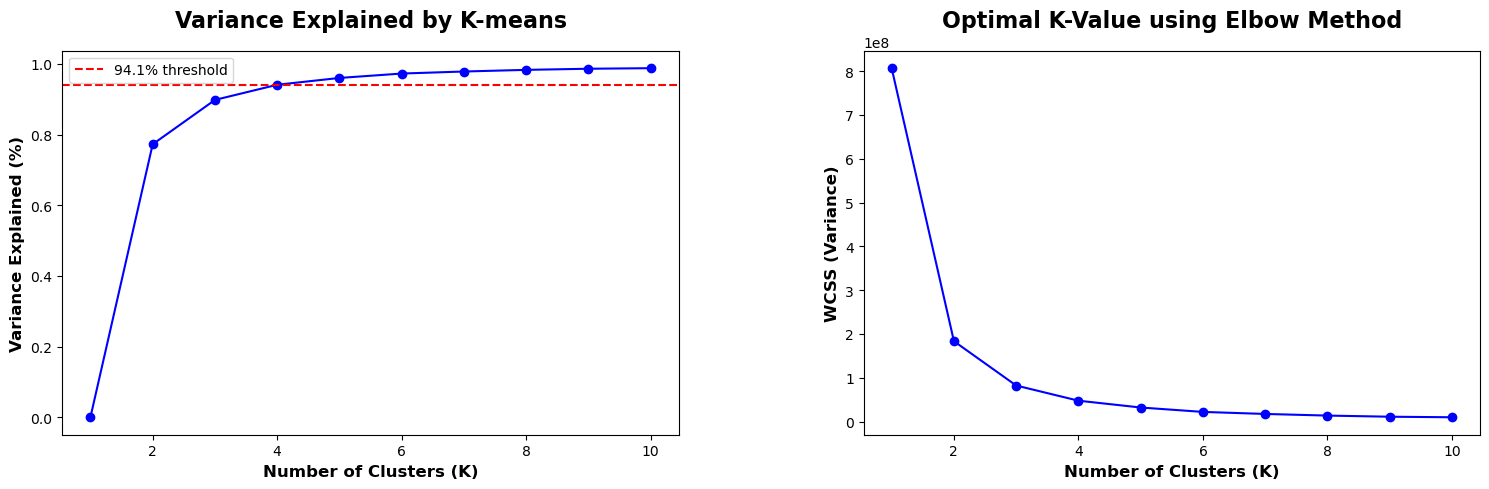

In [7]:
#  Total variance = sum of squared distances from mean
overall_mean = np.mean(np.array(rfm), axis=0)
total_variance = np.sum((np.array(rfm) - overall_mean)**2)

# KMeans Clustering with elbow method
wcss = []                           # Within-Cluster-Sum-of-Squares (WCSS)
explained_variance = []
n_cluster = []
for k in range(1, 11):
    kmeans_elw = KMeans(n_clusters=k, random_state=42)
    kmeans_elw.fit(rfm)
    inertia = kmeans_elw.inertia_
    wcss.append(inertia)
    bcss = total_variance - inertia      # between-cluster sum of squares
    explained_variance.append(bcss / total_variance)
    n_cluster.append(k)

# create dataframe
cluster_dfs = pd.DataFrame([], columns=['no_cluster', 'wcss', 'explained_variance(%)'])
cluster_dfs['no_cluster'] = n_cluster
cluster_dfs['wcss'] = wcss
cluster_dfs['explained_variance(%)'] = explained_variance
cluster_dfs['explained_variance(%)'] = cluster_dfs['explained_variance(%)'].map(lambda x: f'{x:.4f}').astype('float')
cluster_dfs = cluster_dfs.assign(pct_explained_variance=cluster_dfs['explained_variance(%)'].diff())
display(cluster_dfs.head().style.hide(axis='index'))

# plot 
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
# plot no. of clusters with variance explained
value = cluster_dfs.loc[cluster_dfs['no_cluster']==4, 'explained_variance(%)'].iloc[0]
ax[0].plot(range(1, 11), explained_variance, 'bo-')
ax[0].axhline(y=value, color='r', ls='--', label=f'{value:.1%} threshold')
ax[0].set_xlabel('Number of Clusters (K)', fontsize=12, fontweight='bold')
ax[0].set_ylabel('Variance Explained (%)', fontsize=12, fontweight='bold')
ax[0].set_title('Variance Explained by K-means', fontsize=16, fontweight='bold', y=1.04)
ax[0].legend()

# plot no. of clusters with elbow method
ax[1].plot(range(1, 11), wcss, 'bo-')
ax[1].set_xlabel('Number of Clusters (K)', fontsize=12, fontweight='bold')
ax[1].set_ylabel('WCSS (Variance)', fontsize=12, fontweight='bold')
ax[1].set_title('Optimal K-Value using Elbow Method', fontsize=16, fontweight='bold', y=1.04)

plt.tight_layout()
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.show()


In [8]:
# will choose the smallest k that explains at least 94% of the variance, which is k=4

kmeans_elb = KMeans(n_clusters=4, random_state=42)
kmeans_y = kmeans_elb.fit_predict(rfm)

# Add cluster labels to the DataFrame
kmeans_cluster_df = pd.DataFrame(customer_df).copy()
kmeans_cluster_df.loc[:,'Cluster'] = kmeans_y
display(kmeans_cluster_df.head())
print()

# Interpret Clusters
cluster_summary = kmeans_cluster_df.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].agg('mean')
cluster_summary['n_customers'] = kmeans_cluster_df.groupby('Cluster').size()
cluster_summary['percentage_customers'] = ((cluster_summary['n_customers']/cluster_summary['n_customers'].sum())*100).map(lambda x: f'{x:.1f}%')
display_md("**Clusters :**")
display(cluster_summary)



,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Is_parent,Children,Day,Month,Quarter,Year,Monetary,Frequency,Tenure,Cluster
0,5524,1957,Graduation,Single,58138.00,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,58,0,0,4,9,3,2012,1617,22,28,1
1,2174,1954,Graduation,Single,46344.00,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,61,1,2,8,3,1,2014,27,4,9,0
2,4141,1965,Graduation,Partner,71613.00,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,50,0,0,21,8,3,2013,776,20,16,2
3,6182,1984,Graduation,Partner,26646.00,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,31,1,1,10,2,1,2014,53,6,10,0
4,5324,1981,PhD,Partner,58293.00,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,34,1,1,19,1,1,2014,422,14,11,2


**Clusters :**

,Recency,Frequency,Monetary,n_customers,percentage_customers
Cluster,,,,,
0,49.03,6.02,100.49,1058,47.8%
1,51.51,20.06,1767.81,271,12.2%
2,47.13,16.26,575.10,427,19.3%
3,49.34,19.81,1122.58,458,20.7%


#### **2.2. K-means Clustering with Silhouette Analysis:**

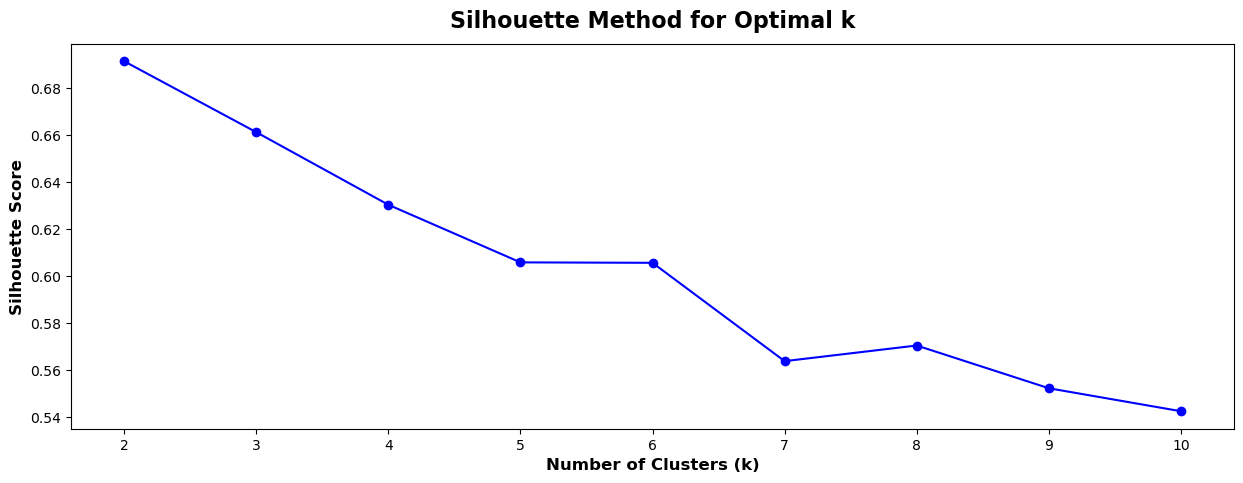

Optimal number of clusters: 2


,Recency,Frequency,Monetary,n_customers,percentage_customers
Cluster,,,,,
0,48.56,8.44,209.71,1417,64.0%
1,49.87,19.90,1314.87,797,36.0%


In [9]:
from sklearn.metrics import silhouette_score

# Calculate silhouette scores for different numbers of clusters
silhouette_scores = []
K = range(2, 11)  # Start from 2 clusters as silhouette score is not defined for 1 cluster

for k in K:
    kmeans_slh = KMeans(n_clusters=k, random_state=42)
    kmeans_slh.fit(rfm)
    score = silhouette_score(rfm, kmeans_slh.labels_)
    silhouette_scores.append(score)

# Plot the silhouette scores
plt.figure(figsize=(15, 5))
plt.plot(K, silhouette_scores, 'bo-')
plt.xlabel('Number of Clusters (k)', fontsize=12, fontweight='bold')
plt.ylabel('Silhouette Score', fontsize=12, fontweight='bold')
plt.title('Silhouette Method for Optimal k', fontsize=16, fontweight='bold', y=1.02)
plt.show()

# Find the optimal number of clusters (highest silhouette score)
optimal_k = K[np.argmax(silhouette_scores)]
print(f"Optimal number of clusters: {optimal_k}")

# Perform K-means clustering with the optimal number of clusters
kmeans_slh = KMeans(n_clusters=optimal_k, random_state=42)
p = kmeans_slh.fit_predict(rfm)

# Add cluster labels to the DataFrame
cluster_data = pd.DataFrame(customer_df)
cluster_data.loc[:,'Cluster'] = p

# Interpret clusters
cluster_analysis = cluster_data.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].agg('mean')
cluster_analysis['n_customers'] = cluster_data.groupby('Cluster').size()
cluster_analysis['percentage_customers'] = ((cluster_analysis['n_customers']/cluster_analysis['n_customers'].sum())*100).map(lambda x: f'{x:.1f}%')
display(cluster_analysis)


#### **2.3. Gaussian Mixture Model with BIC**

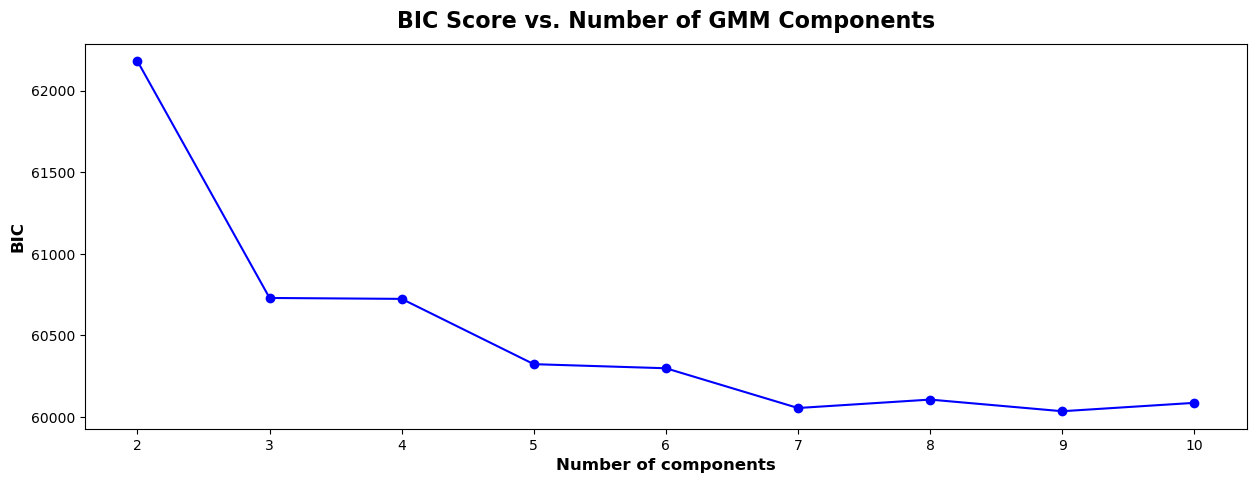

The optimal number of components based on BIC: 9



,Recency,Frequency,Monetary,n_customers,percentage_customers
Cluster,,,,,
0,48.40,4.57,45.47,654,29.5%
1,52.69,18.10,1293.59,295,13.3%
2,48.72,20.86,842.20,351,15.9%
3,55.54,22.52,1194.36,67,3.0%
4,49.51,17.32,1915.25,138,6.2%
5,51.57,8.17,179.66,369,16.7%
6,38.27,20.52,1572.93,60,2.7%
7,43.63,17.78,688.08,60,2.7%
8,44.39,13.45,417.59,220,9.9%


In [10]:
from sklearn.mixture import GaussianMixture

# compute BIC and silhouette scores for different numbers of components
n_components_range = range(2, 11)
bic = []
silhouette_scores = []

for n_components in n_components_range:
    # Fit Gaussian Mixture Model
    gmm = GaussianMixture(n_components=n_components, random_state=42)
    gmm.fit(rfm)

    # Calculate BIC score
    bic.append(gmm.bic(rfm))

# Plot the BIC scores
print()
plt.figure(figsize=(15, 5))
plt.plot(n_components_range, bic, 'bo-')
plt.xlabel('Number of components', fontsize=12, fontweight='bold')
plt.ylabel('BIC', fontsize=12, fontweight='bold')
plt.title('BIC Score vs. Number of GMM Components', fontsize=16, fontweight='bold', y=1.02)
plt.show()

# Find the optimal number of components (lowest BIC)
optimal_components = n_components_range[np.argmin(bic)]
print(f"The optimal number of components based on BIC: {optimal_components}\n")

# Fit GMM with the optimal number of components
gmm = GaussianMixture(n_components=optimal_components, random_state=42)
q = gmm.fit_predict(rfm)

# Add cluster labels to the original dataframe
gmm_clustering_data = pd.DataFrame(customer_df)
gmm_clustering_data.loc[:, 'Cluster'] = q

# Interpret clusters
cluster_analysis = gmm_clustering_data.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].agg('mean')
cluster_analysis['n_customers'] = gmm_clustering_data.groupby('Cluster').size()
cluster_analysis['percentage_customers'] = ((cluster_analysis['n_customers']/cluster_analysis['n_customers'].sum())*100).map(lambda x: f'{x:.1f}%')
display(cluster_analysis)


**Clustering Analysis of Customers in the customer personality Dataset**

| Technique | Optimal Number of Clusters |
|---|---:|
| __K-means Clustering + Elbow Method__ | 4 |
| __K-means Clustering + Silhouette Score__ | 2 |
| __Gaussian Mixture Model (GMM) + BIC__ | 9 |


To maintain interpretability and provide a clear representation of customer personalities, the **K-means clustering solution optimized with the elbow method** was selected, yielding four meaningful customer segments.


### **KMeans Cluster With Elbow Method : Best Technique**

In [11]:
# K-means cluster + elbow method
centers = kmeans_elb.cluster_centers_
display_md(f"**Cluster Label** : {kmeans_elb.labels_}")
print(f"Cluster Centers : \n{centers}", end="\n\n")

cluster_names = {
    0 : 'Bronze',
    1 : 'Diamond',
    2 : 'Silver',
    3 : 'Gold'
}

kmeans_cluster_df['Cluster_Label'] = kmeans_cluster_df['Cluster'].map(cluster_names)

display(cluster_summary)


**Cluster Label** : [1 0 2 ... 3 2 0]

Cluster Centers : 
[[  49.05288008    6.02360718  100.71954674]
 [  51.50922509   20.05904059 1767.81180812]
 [  47.0117096    16.26697892  576.29742389]
 [  49.404814     19.82056893 1123.17724289]]



,Recency,Frequency,Monetary,n_customers,percentage_customers
Cluster,,,,,
0,49.03,6.02,100.49,1058,47.8%
1,51.51,20.06,1767.81,271,12.2%
2,47.13,16.26,575.10,427,19.3%
3,49.34,19.81,1122.58,458,20.7%


#### **2.4 ANOVA +Tukey'HSD Test**

In [12]:
import pandas as pd
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# RFM features
rfm_features = ['Recency', 'Frequency', 'Monetary']

# Store results
anova_results = []
tukey_results = {}

# =========================================================
# STEP 1: ANOVA
# =========================================================

for feature in rfm_features:

    # Get values for each cluster
    groups = [
        group[feature].dropna().values
        for cluster, group in kmeans_cluster_df.groupby('Cluster_Label')
    ]

    # One-way ANOVA
    f_stat, p_value = stats.f_oneway(*groups)

    anova_results.append({
        'Feature': feature,
        'F_Statistic': f_stat,
        'P_Value': p_value,
        'Significant': 'Yes' if p_value < 0.05 else 'No'
    })


# Convert ANOVA results to DataFrame
anova_df = pd.DataFrame(anova_results)

print("========== ANOVA RESULTS ==========")
display(anova_df.round(4))


# =========================================================
# STEP 2: TUKEY HSD
# =========================================================

for feature in rfm_features:

    tukey = pairwise_tukeyhsd(
        endog=kmeans_cluster_df[feature],
        groups=kmeans_cluster_df['Cluster_Label'],
        alpha=0.05
    )

    tukey_df = pd.DataFrame(
        tukey._results_table.data[1:],
        columns=tukey._results_table.data[0]
    )

    tukey_results[feature] = tukey_df

    print("\n" + "=" * 70)
    print(f"TUKEY HSD RESULTS — {feature}")
    print("=" * 70)

    display(tukey_df)


# =========================================================
# STEP 3: COMBINED TUKEY RESULTS
# =========================================================

all_tukey = []

for feature, result in tukey_results.items():

    result = result.copy()
    result.insert(0, 'Feature', feature)

    all_tukey.append(result)

tukey_summary = pd.concat(
    all_tukey,
    ignore_index=True
)

print("\n========== COMBINED TUKEY RESULTS ==========")
display(tukey_summary)


========== ANOVA RESULTS ==========


,Feature,F_Statistic,P_Value,Significant
0,Recency,1.29,0.27,No
1,Frequency,2732.02,0.00,Yes
2,Monetary,12203.57,0.00,Yes



TUKEY HSD RESULTS — Recency


,group1,group2,meandiff,p-adj,lower,upper,reject
0,Bronze,Diamond,2.47,0.59,-2.59,7.54,False
1,Bronze,Gold,0.30,1.00,-3.86,4.46,False
2,Bronze,Silver,-1.91,0.66,-6.17,2.36,False
3,Diamond,Gold,-2.17,0.76,-7.88,3.53,False
4,Diamond,Silver,-4.38,0.21,-10.16,1.40,False
5,Gold,Silver,-2.21,0.67,-7.21,2.80,False



TUKEY HSD RESULTS — Frequency


,group1,group2,meandiff,p-adj,lower,upper,reject
0,Bronze,Diamond,14.04,0.00,13.46,14.62,True
1,Bronze,Gold,13.79,0.00,13.31,14.27,True
2,Bronze,Silver,10.25,0.00,9.76,10.74,True
3,Diamond,Gold,-0.25,0.75,-0.91,0.40,False
4,Diamond,Silver,-3.79,0.00,-4.46,-3.13,True
5,Gold,Silver,-3.54,0.00,-4.12,-2.97,True



TUKEY HSD RESULTS — Monetary


,group1,group2,meandiff,p-adj,lower,upper,reject
0,Bronze,Diamond,1667.32,0.00,1642.12,1692.52,True
1,Bronze,Gold,1022.09,0.00,1001.38,1042.79,True
2,Bronze,Silver,474.61,0.00,453.39,495.83,True
3,Diamond,Gold,-645.23,0.00,-673.60,-616.86,True
4,Diamond,Silver,-1192.71,0.00,-1221.46,-1163.96,True
5,Gold,Silver,-547.48,0.00,-572.38,-522.58,True



========== COMBINED TUKEY RESULTS ==========


,Feature,group1,group2,meandiff,p-adj,lower,upper,reject
0,Recency,Bronze,Diamond,2.47,0.59,-2.59,7.54,False
1,Recency,Bronze,Gold,0.30,1.00,-3.86,4.46,False
2,Recency,Bronze,Silver,-1.91,0.66,-6.17,2.36,False
3,Recency,Diamond,Gold,-2.17,0.76,-7.88,3.53,False
4,Recency,Diamond,Silver,-4.38,0.21,-10.16,1.40,False
5,Recency,Gold,Silver,-2.21,0.67,-7.21,2.80,False
6,Frequency,Bronze,Diamond,14.04,0.00,13.46,14.62,True
7,Frequency,Bronze,Gold,13.79,0.00,13.31,14.27,True
8,Frequency,Bronze,Silver,10.25,0.00,9.76,10.74,True
9,Frequency,Diamond,Gold,-0.25,0.75,-0.91,0.40,False


__Interpretation__

**Monetary value differed significantly across the customer clusters (p < 0.05). Tukey's HSD test further showed that Bronze customers differed significantly from Gold and Diamond customers, confirming that the clusters represent distinct levels of customer spending.**

Based on the __ANOVA and Tukey HSD__ tests, Frequency and Monetary show significant differences across clusters. Therefore, these two statistically significant behavioural metrics are selected for __customer clustering and segmentation__.


#### **2.4. Cluster Labeling based on RFM**

**Metrics are Recency, Frequency, Monetary**

| Cluster | Segment | Size | RFM Characteristics | Interpretation | Business Meaning | 
|---|---|---:|---|---|---|
| **Cluster 0** | **Bronze / Low-value Customers** | **47.8%** | Recency: 49.03 (moderate–high)<br>Frequency: 6.02 (very low)<br>Monetary: 100.49 (very low) | Infrequent and low-spending customers who have not purchased recently. They contribute the least revenue but form the largest portion of the customer base. | Weak engagement and low loyalty; high potential churn risk; likely one-time or inactive customers. | 
| **Cluster 1** | **Diamond / VIP Customers** | **12.2%** | Recency: 51.51 (moderate)<br>Frequency: 20.06 (highest)<br>Monetary: 1767.81 (highest by far) | Frequent purchasers who spend significantly more than other segments, making them the most profitable segment. | Core revenue drivers; likely repeat buyers across channels. | 
| **Cluster 2** | **Silver / Moderate-value Customers** | **19.3%** | Recency: 47.13 (best/most recent)<br>Frequency: 16.26 (moderate–high)<br>Monetary: 575.10 (moderate–low) | Active and relatively recent buyers, but their spending is moderate. They engage fairly often but make low-value purchases. | Good engagement but low basket value; potential to become higher-value customers; responsive to marketing. | 
| **Cluster 3** | **Gold / High-value Customers** | **20.7%** | Recency: 49.34 (moderate)<br>Frequency: 19.81 (high)<br>Monetary: 1122.58 (high) | Frequent shoppers with solid spending levels, but not as valuable as Cluster 1. | Strong repeat behavior; medium-to-high revenue contribution; close to the premium segment. | 


***


#### **2.5. Cluster Visualization**

**2.5.1. Cluster-wise RFM distribution**

In [13]:
display(kmeans_cluster_df.head(2))

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Is_parent,Children,Day,Month,Quarter,Year,Monetary,Frequency,Tenure,Cluster,Cluster_Label
0,5524,1957,Graduation,Single,58138.00,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,58,0,0,4,9,3,2012,1617,22,28,1,Diamond
1,2174,1954,Graduation,Single,46344.00,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,61,1,2,8,3,1,2014,27,4,9,0,Bronze


Cluster_Label
Bronze     1058
Gold        458
Silver      427
Diamond     271
Name: count, dtype: int64

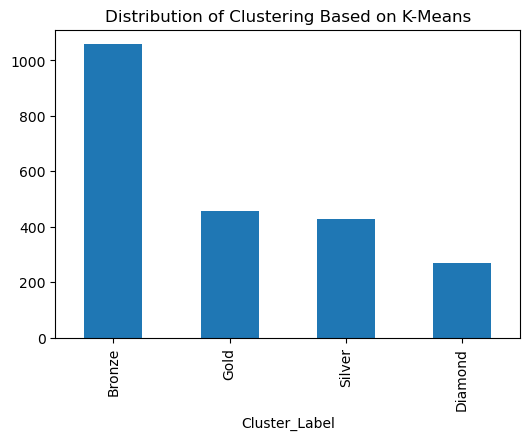

In [14]:
cluster_values = kmeans_cluster_df['Cluster_Label'].value_counts()
display(cluster_values)

cluster_values.plot(kind='bar', figsize=(6, 4), title='Distribution of Clustering Based on K-Means')
plt.show()


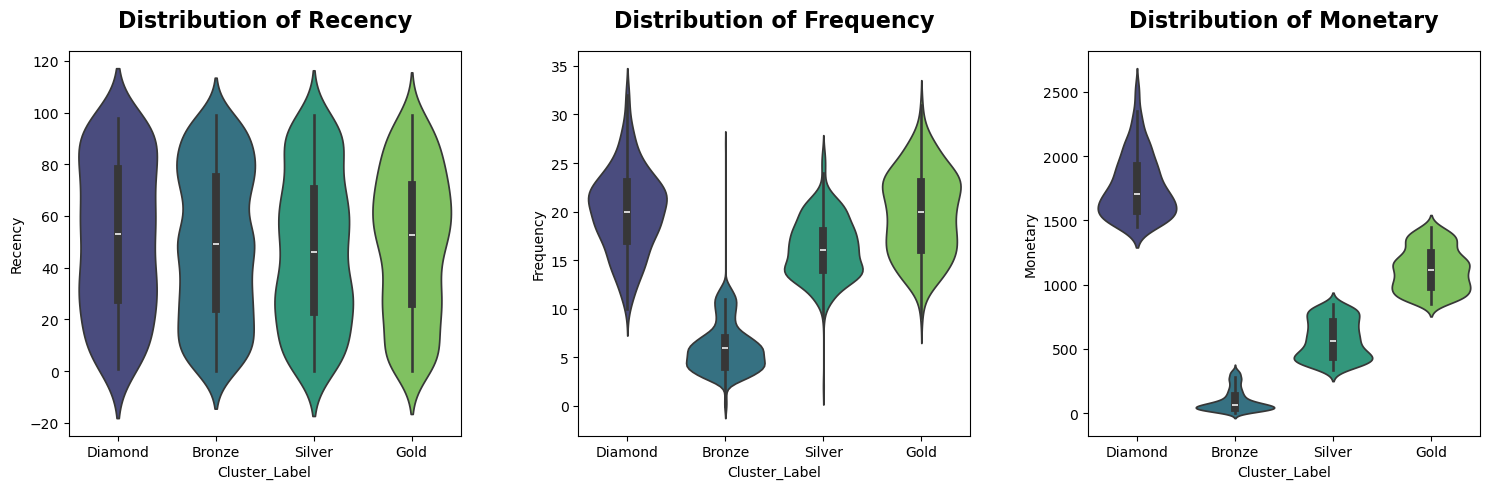

In [15]:

# Violin Plots to see data distribution and density per cluster
features_to_plot = ['Recency', 'Frequency', 'Monetary']

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
#ax= ax.flatten()

for i, col in enumerate(features_to_plot):
    # Violin plots show the median, range, and where the bulk of the data lies
    sns.violinplot(x='Cluster_Label', y=col, data=kmeans_cluster_df, palette='viridis', ax=ax[i])
    ax[i].set_title(f'Distribution of {col}', fontsize=16, fontweight='bold', y=1.04)
    
plt.tight_layout()
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.show()



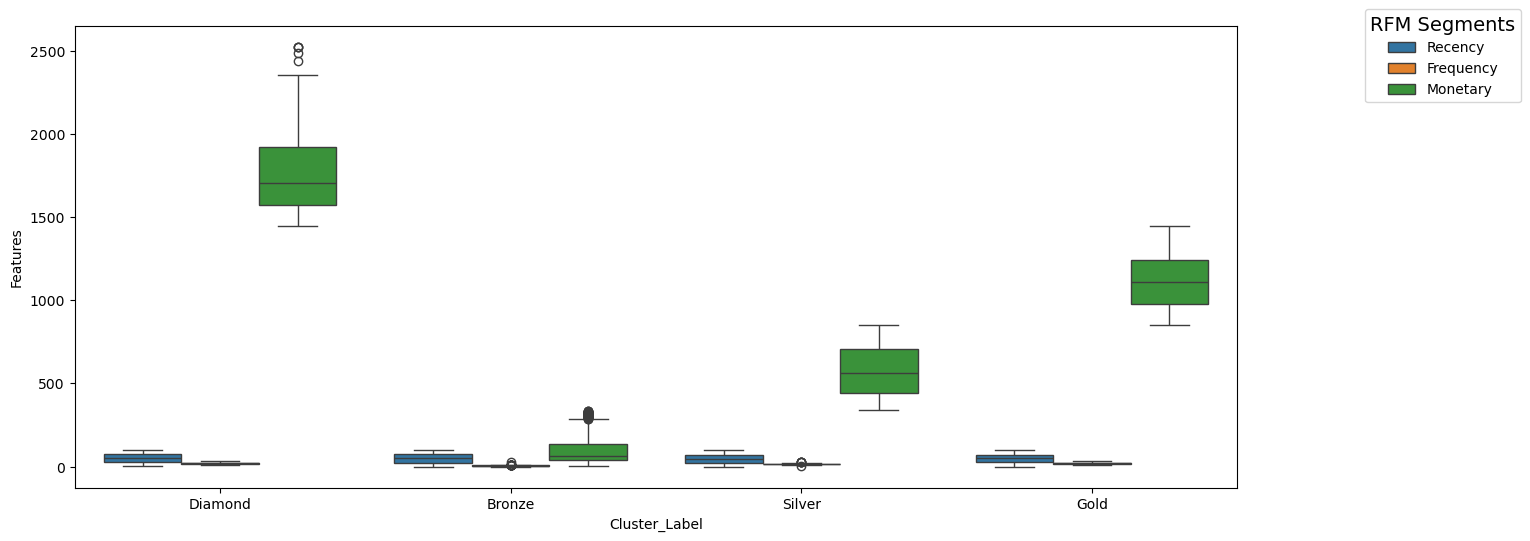

In [16]:
rfm_df = pd.melt(kmeans_cluster_df, id_vars='Cluster_Label', value_vars=['Recency', 'Frequency', 'Monetary'], value_name='Features')

# visualization
fig, ax = plt.subplots(figsize=(15, 6))
sns.boxplot(data=rfm_df, x='Cluster_Label', y='Features', hue='variable')
plt.legend(title='RFM Segments', title_fontsize=14, bbox_to_anchor=(1.25, 1.05), loc='upper right', fancybox=True)
plt.show()


**2.5.2. Cluster by Income & Monetary**

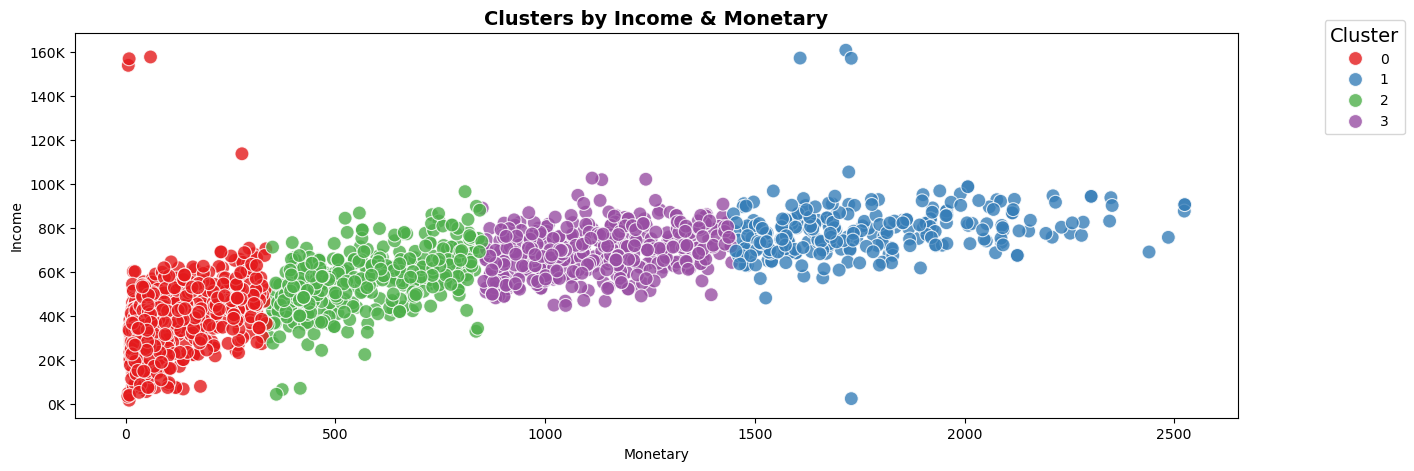

In [17]:
import matplotlib as mpl
from matplotlib.ticker import FuncFormatter
fig, ax = plt.subplots(figsize=(15, 5))

sns.scatterplot(
    data=kmeans_cluster_df,
    x='Monetary',
    y='Income',
    hue='Cluster',              
    palette='Set1',      
    alpha=0.8,                   
    s=100                        
)

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
ax.set_title("Clusters by Income & Monetary", fontsize=14, fontweight='bold')
ax.legend(title='Cluster', title_fontsize=14, bbox_to_anchor=(1.15, 1.05), loc='upper right', fancybox=True)

plt.show()



**Insights**

- The 4 clusters can be easily identified from the plot above.
- Those who earn more also spend more.

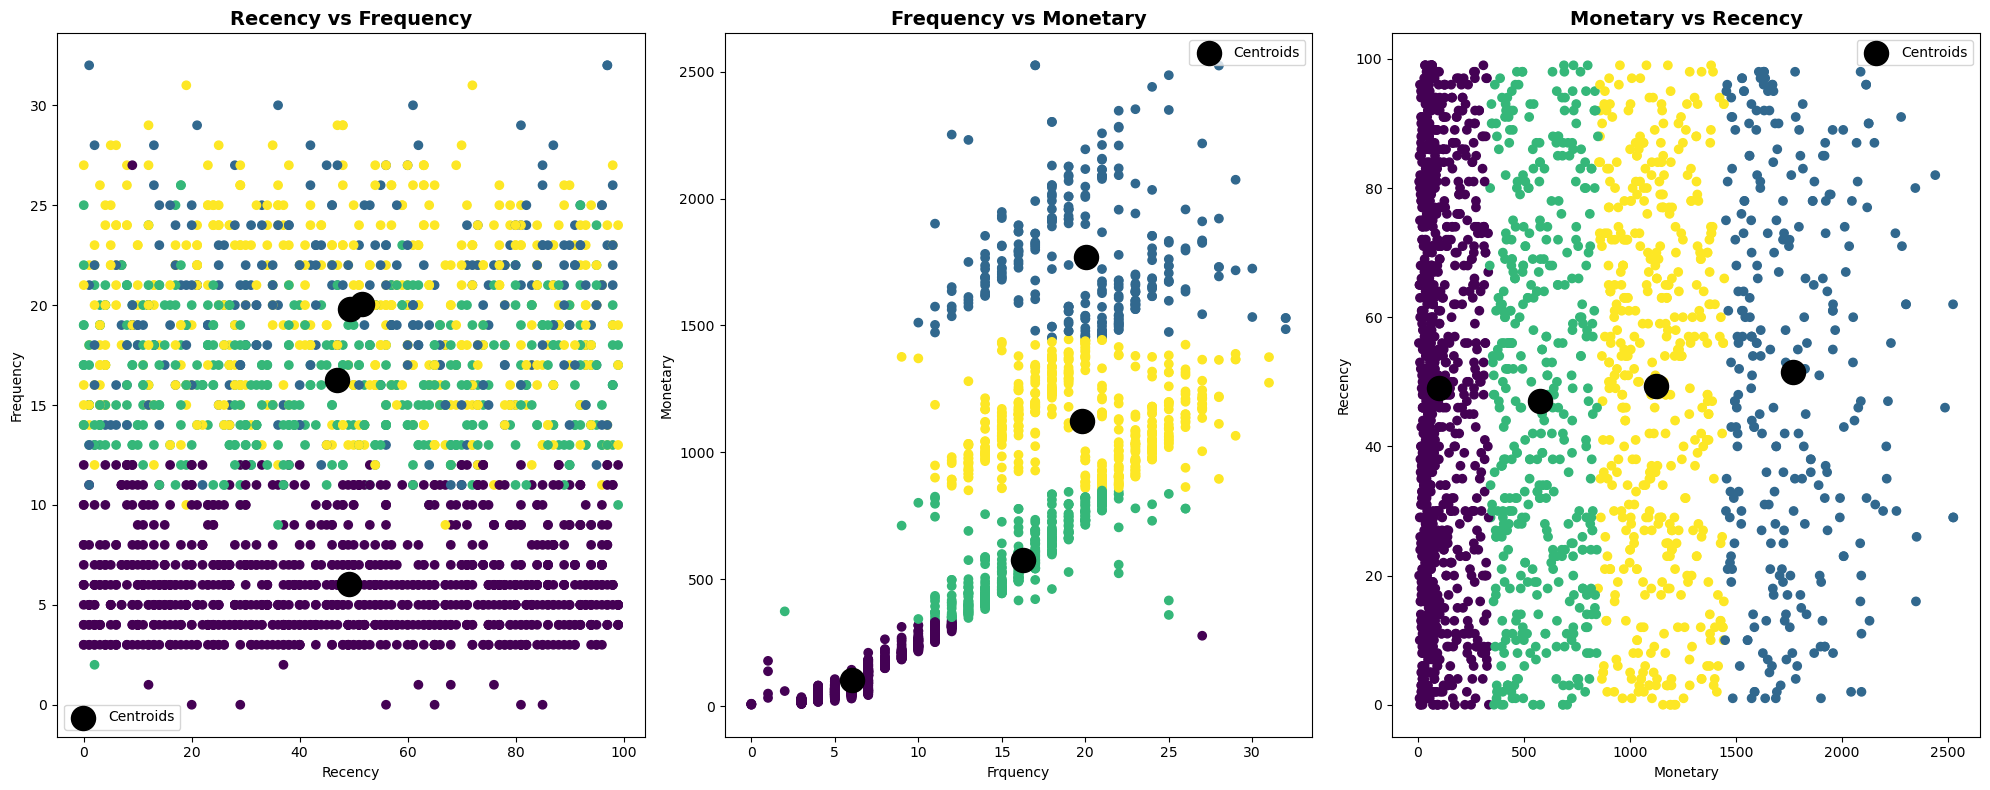

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(20, 8))

# Recency vs Frequency
ax[0].scatter(
    kmeans_cluster_df['Recency'],
    kmeans_cluster_df['Frequency'], 
    c=kmeans_cluster_df['Cluster']
)

ax[0].scatter(centers[:, 0], centers[:, 1], s=300, color='k', label='Centroids')
ax[0].set_title("Recency vs Frequency", fontsize=14, fontweight='bold')
ax[0].set_xlabel("Recency")
ax[0].set_ylabel("Frequency")
ax[0].legend(loc='best')

# Frequency vs Monetary
ax[1].scatter(
    kmeans_cluster_df['Frequency'],
    kmeans_cluster_df['Monetary'], 
    c=kmeans_cluster_df['Cluster']
    )
ax[1].scatter(centers[:, 1], centers[:, 2], s=300, color='k', label='Centroids')
ax[1].set_title("Frequency vs Monetary", fontsize=14, fontweight='bold')
ax[1].set_xlabel("Frquency")
ax[1].set_ylabel("Monetary")
ax[1].legend(loc='best')

# Monetary vs Recency
ax[2].scatter(
    kmeans_cluster_df['Monetary'],
    kmeans_cluster_df['Recency'], 
    c=kmeans_cluster_df['Cluster']
    )
ax[2].scatter(centers[:, 2], centers[:, 0], s=300, color='k', label='Centroids')
ax[2].set_title("Monetary vs Recency", fontsize=14, fontweight='bold')
ax[2].set_xlabel("Monetary")
ax[2].set_ylabel("Recency")
ax[2].legend(loc='best')

plt.tight_layout()
plt.subplots_adjust(hspace=0.01)
plt.show()


#### **2.7. Customer Profiling by Cluster**

In [19]:
# ---------------------------------------------------------
# 1. Overall averages
# ---------------------------------------------------------
rfm_cols = ['Recency', 'Frequency', 'Monetary']
overall_rfm = kmeans_cluster_df[rfm_cols].mean()

overall_revenue = kmeans_cluster_df['Monetary'].sum()
overall_customers = len(kmeans_cluster_df)
overall_revenue_per_customer = overall_revenue / overall_customers

print("Overall RFM Average:")
print(overall_rfm)

print("\nOverall Revenue:", overall_revenue)
print("Overall Revenue per Customer:", overall_revenue_per_customer)


# ---------------------------------------------------------
# 2. Cluster profiling
# ---------------------------------------------------------

cluster_profile = kmeans_cluster_df.groupby('Cluster_Label').agg(
    Customers=('ID', 'count'),
    Customer_percentage = ('ID', lambda x : 100 * len(x)/len(kmeans_cluster_df)),
    Total_Revenue=('Monetary', 'sum'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Revenue_per_customer=('Monetary', 'mean')
)

# ---------------------------------------------------------
# 3. Revenue contribution
# ---------------------------------------------------------

cluster_profile['Revenue_%'] = (
    cluster_profile['Total_Revenue'] /
    cluster_profile['Total_Revenue'].sum() * 100
)

# ---------------------------------------------------------
# 4. Compare cluster RFM with overall average
# ---------------------------------------------------------

cluster_profile['Recency_%_vs_Overall'] = (
    (cluster_profile['Avg_Recency'] - overall_rfm['Recency'])
    / overall_rfm['Recency']
) * 100


cluster_profile['Frequency_%_vs_Overall'] = (
    (cluster_profile['Avg_Frequency'] - overall_rfm['Frequency'])
    / overall_rfm['Frequency']
) * 100


cluster_profile['Monetary_%_vs_Overall'] = (
    (cluster_profile['Revenue_per_customer'] - overall_rfm['Monetary'])
    / overall_rfm['Monetary']
) * 100


display_md("**Customer Cluster Profile :**")
display(cluster_profile.round(2))


Overall RFM Average:
Recency      49.03
Frequency    12.57
Monetary    607.55
dtype: float64

Overall Revenue: 1345110
Overall Revenue per Customer: 607.5474254742547


**Customer Cluster Profile :**

,Customers,Customer_percentage,Total_Revenue,Avg_Recency,Avg_Frequency,Revenue_per_customer,Revenue_%,Recency_%_vs_Overall,Frequency_%_vs_Overall,Monetary_%_vs_Overall
Cluster_Label,,,,,,,,,,
Bronze,1058,47.79,106323,49.03,6.02,100.49,7.90,0.00,-52.11,-83.46
Diamond,271,12.24,479077,51.51,20.06,1767.81,35.62,5.05,59.64,190.98
Gold,458,20.69,514142,49.34,19.81,1122.58,38.22,0.62,57.63,84.77
Silver,427,19.29,245568,47.13,16.26,575.10,18.26,-3.88,29.44,-5.34


**Brief Statistical Interpretation**

| Cluster | Statistical Summary |
|---|---|
| **Bronze** | Largest segment (47.79%) but lowest revenue contribution per customer. Frequency is 52.11% below the overall average and Monetary value is 83.46% below average. |
| **Silver** | Represents 19.29% of customers and contributes 18.26% of revenue. Customers are relatively recent and have above-average Frequency, indicating good engagement but moderate spending. |
| **Gold** | Represents 20.69% of customers but generates 38.22% of revenue. Frequency and Monetary values are substantially above the overall averages, making this a major revenue-generating segment. |
| **Diamond** | Smallest segment (12.24%) but highest-value customers. Revenue per customer is 1,767.81, while Frequency and Monetary values are 59.64% and 190.98% above average, respectively. |



**Business Recommendation**

| Segment | Key Findings | Customer Behaviour | Recommended Strategy |
|---|---|---|---|
| **Bronze** | 47.79% customers, but only 7.90% revenue | Very low frequency and monetary value; low-value segment | Reactivation, increase average basket size, discounts, and engagement campaigns |
| **Silver** | 19.29% customers and 18.26% revenue | Recent and relatively frequent buyers with moderate spending | Upselling and cross-selling to increase value |
| **Gold** | 20.69% customers but 38.22% revenue | High frequency and high spending; major revenue contributor | Retention, loyalty rewards, and premium offers |
| **Diamond** | Only 12.24% customers but 35.62% revenue | Highest frequency, monetary value, and revenue per customer | VIP retention, personalized offers, and exclusive benefits |
| **Overall** | **32.93% of customers generate 73.84% of revenue** | Revenue is highly concentrated among Gold and Diamond customers | Prioritize retention of high-value customers while upgrading Silver and reactivating Bronze |



## **3.  Traditional RFM Segmentation**

#### **3.1. RFM Quartiles Segmentation**

In [20]:
customer_df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Is_parent,Children,Day,Month,Quarter,Year,Monetary,Frequency,Tenure
0,5524,1957,Graduation,Single,58138.00,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,58,0,0,4,9,3,2012,1617,22,28
1,2174,1954,Graduation,Single,46344.00,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,61,1,2,8,3,1,2014,27,4,9
2,4141,1965,Graduation,Partner,71613.00,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,50,0,0,21,8,3,2013,776,20,16
3,6182,1984,Graduation,Partner,26646.00,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,31,1,1,10,2,1,2014,53,6,10
4,5324,1981,PhD,Partner,58293.00,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,34,1,1,19,1,1,2014,422,14,11


In [21]:
rfm_data = customer_df[['ID', 'Recency', 'Frequency', 'Monetary']].copy()

# compute average spending per transaction
rfm_data = rfm_data.assign(
    Avg_spending = customer_df['Monetary']/customer_df['Frequency']
)

display(rfm_data.head())


,ID,Recency,Frequency,Monetary,Avg_spending
0,5524,58,22,1617,73.50
1,2174,38,4,27,6.75
2,4141,26,20,776,38.80
3,6182,26,6,53,8.83
4,5324,94,14,422,30.14


RFM analysis is a popular way to study customer behavior. To do this, compute quantiles for the RFM features and divide customers into four quartiles commonly called **Quartiles Segmentation or RFM Quartiles Scoring**.

- Recency: 1(High) and 4(Low)
- Frequency and Monetary: 1(Low) and 4(High)
- Scaling customers from 1–4 creates 64 possible RFM scores (4x4x4), ranging from (111 to 444). Since it's not practical to analyze all 64 groups separately, marketers usually simplify by focusing only on the Recency and Frequency scores.


In [22]:

# 1. Compute quantiles for each RFM feature
quantiles = rfm_data[['Recency','Frequency','Monetary']].quantile([0.25,0.50,0.75]).to_dict()

# 2. Define scoring functions
# Benchmark to give score for recency indicator

def r_score(x, q=quantiles):
    if x <= q['Recency'][0.25]:
        return 4
    elif x <= q['Recency'][0.50]:
        return 3
    elif x <= q['Recency'][0.75]:
        return 2
    else:
        return 1

# Benchmark to give score for frequency & monetary indicator

def fm_score(x, col, q=quantiles):
    if x <= q[col][0.25]:
        return 1
    elif x <= q[col][0.50]:
        return 2
    elif x <= q[col][0.75]:
        return 3
    else:
        return 4

# 3. Apply scoring
rfm_data['R'] = rfm_data['Recency'].apply(lambda x: r_score(x))
rfm_data['F'] = rfm_data['Frequency'].apply(lambda x: fm_score(x, col='Frequency'))
rfm_data['M'] = rfm_data['Monetary'].apply(lambda x: fm_score(x, col='Monetary'))

# 4. Combine into RFM score
rfm_data['RFM_Score'] = rfm_data['R'].map(str) + rfm_data['F'].map(str) + rfm_data['M'].map(str)
display(rfm_data.head())

# Now you have quartile-based RFM scores for segmentation


,ID,Recency,Frequency,Monetary,Avg_spending,R,F,M,RFM_Score
0,5524,58,22,1617,73.50,2,4,4,244
1,2174,38,4,27,6.75,3,1,1,311
2,4141,26,20,776,38.80,3,4,3,343
3,6182,26,6,53,8.83,3,1,1,311
4,5324,94,14,422,30.14,1,3,3,133


We add a "Segments" column to `rfm_data` by applying a `classifier` function. This function evaluates each customer's RFM quartile scores against predefined rules and assigns them to behavior groups such as Champions, Loyal Customers, or Potential Loyalists. In effect, it translates raw RFM patterns into clear, actionable customer segments.


In [23]:
# creating five quartiles based on recency and frequency metrics, excluding monetary
RF_segmentation_map = {
    r'[1-2][1-2]': 'Hibernating',
    r'[1-2][3-4]': 'At Risk',
    r'3[1-2]': 'Need Attention',
    r'3[3-4]': 'Potential Loyalists',
    r'4[1-2]': 'Loyal Customers',
    r'4[3-4]': 'Champions'
}

rfm_data['RFM_score_segment'] = rfm_data['R'].map(str) + rfm_data['F'].map(str)
rfm_data['RFM_score_segment'] = rfm_data['RFM_score_segment'].replace(RF_segmentation_map, regex=True)
display(rfm_data.head())


,ID,Recency,Frequency,Monetary,Avg_spending,R,F,M,RFM_Score,RFM_score_segment
0,5524,58,22,1617,73.50,2,4,4,244,At Risk
1,2174,38,4,27,6.75,3,1,1,311,Need Attention
2,4141,26,20,776,38.80,3,4,3,343,Potential Loyalists
3,6182,26,6,53,8.83,3,1,1,311,Need Attention
4,5324,94,14,422,30.14,1,3,3,133,At Risk


In [24]:
score_counts = rfm_data['RFM_score_segment'].value_counts()
display_md("**RFM Score Segment Counts :**")
display(score_counts)


**RFM Score Segment Counts :**

RFM_score_segment
At Risk                555
Hibernating            548
Loyal Customers        287
Need Attention         282
Champions              274
Potential Loyalists    268
Name: count, dtype: int64

- **Champions**: Buy often, spend the most, and purchased recently.

- **Loyal Customers**: Regular buyers who respond well to promotions.

- **Potential Loyalists**: Newer customers with average buying frequency.

- **New Customers**: Just purchased, but not very often.

- **Promising**: Shopped recently but spent little.

- **Customers Needing Attention**: Good spenders overall, but haven’t bought very recently.

- **About to Sleep**: Low recency and frequency; risk of losing them.

- **At Risk**: Used to buy often, but last purchase was long ago.

- **Can't Lose Them**: Once frequent buyers, now inactive for a long time.

- **Hibernating**: Few orders and last purchase was long ago; likely lost.

After segmenting customers, we can count how many belong to each group, design tailored strategies for them, and concentrate on the segments that matter most.

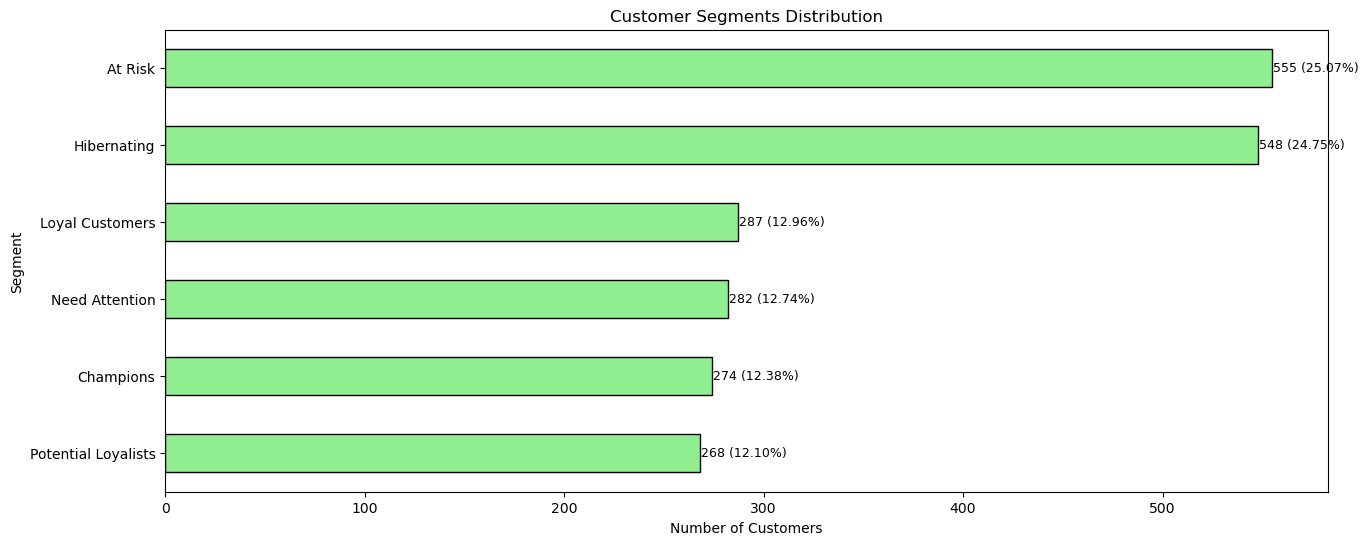

In [25]:
segment_counts = rfm_data['RFM_score_segment'].value_counts().sort_values(ascending=True)

# Visualize this using bar plot
plt.figure(figsize=(15, 6))
segment_counts.plot(kind='barh', color='lightgreen', ec='k')

plt.title("Customer Segments Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Segment")

# Annotate each bar with its value
for i, (segment, value) in enumerate(zip(segment_counts.index, segment_counts.values)):
    plt.text(value+0.5, i, f'{value} ({value/segment_counts.values.sum()*100:.2f}%)', va='center', fontsize=9)  # +5 shifts text slightly right

plt.show()


In [26]:
rfm_data.groupby('RFM_score_segment').agg({'Recency': ['mean','median','min','max'],
                                           'Frequency': ['mean','median','min','max'],
                                           'Monetary': ['mean','median','min','max','count']}).round(1)


Recency                Frequency                Monetary  \
                       mean median min max      mean median min max     mean   
RFM_score_segment                                                              
At Risk               73.60  73.00  50  99     18.90  19.00  13  32  1093.20   
Champions             11.30  11.00   0  24     19.00  19.00  13  32  1052.90   
Hibernating           74.70  76.00  50  99      6.40   6.00   0  12   145.50   
Loyal Customers       12.00  12.00   0  24      6.20   6.00   0  12   132.20   
Need Attention        37.20  37.00  25  49      6.20   6.00   0  12   125.80   
Potential Loyalists   36.40  36.00  25  49     19.10  18.00  13  30  1107.20   

                                              
                     median  min   max count  
RFM_score_segment                             
At Risk             1043.00  347  2524   555  
Champions           1012.00  277  2349   274  
Hibernating           72.00    5  2252   548  
Loyal Customers       72.00    6  1901   287  
Need Attention        61.50    9  1635   282  
Potential Loyalists 1074.50  362  2525   268

#### **3.2. RFM Total Score-Based Segmentation**

In [27]:
rfm_data['RFM_Points'] = rfm_data[['R', 'F', 'M']].sum(axis=1)
display(rfm_data.head())


,ID,Recency,Frequency,Monetary,Avg_spending,R,F,M,RFM_Score,RFM_score_segment,RFM_Points
0,5524,58,22,1617,73.50,2,4,4,244,At Risk,10
1,2174,38,4,27,6.75,3,1,1,311,Need Attention,5
2,4141,26,20,776,38.80,3,4,3,343,Potential Loyalists,10
3,6182,26,6,53,8.83,3,1,1,311,Need Attention,5
4,5324,94,14,422,30.14,1,3,3,133,At Risk,7


In [28]:
def assign_segment(rfm_total):
    if rfm_total >= 11:
        return "Champions"
    elif rfm_total >= 9:
        return "Loyal Customers"
    elif rfm_total >= 7:
        return "Potential Loyalists"
    elif rfm_total >= 5:
        return "Need Attention"
    elif rfm_total == 4:
        return "At Risk"
    elif rfm_total == 3:
        return "Hibernating"


rfm_data["RFM_point_segment"] = rfm_data["RFM_Points"].apply(assign_segment)
display(rfm_data.head())


,ID,Recency,Frequency,Monetary,Avg_spending,R,F,M,RFM_Score,RFM_score_segment,RFM_Points,RFM_point_segment
0,5524,58,22,1617,73.50,2,4,4,244,At Risk,10,Loyal Customers
1,2174,38,4,27,6.75,3,1,1,311,Need Attention,5,Need Attention
2,4141,26,20,776,38.80,3,4,3,343,Potential Loyalists,10,Loyal Customers
3,6182,26,6,53,8.83,3,1,1,311,Need Attention,5,Need Attention
4,5324,94,14,422,30.14,1,3,3,133,At Risk,7,Potential Loyalists


In [29]:
point_counts = rfm_data['RFM_point_segment'].value_counts()
display_md("**RFM Point Segment Counts :**")
display(point_counts)


**RFM Point Segment Counts :**

RFM_point_segment
Need Attention         555
Loyal Customers        551
Potential Loyalists    525
Champions              280
At Risk                161
Hibernating            142
Name: count, dtype: int64

In [30]:
rfm_data.groupby('RFM_point_segment').agg({'Recency': ['mean','median','min','max'],
                                           'Frequency': ['mean','median','min','max'],
                                           'Monetary': ['mean','median','min','max','count']}).round(1)


Recency                Frequency                Monetary  \
                       mean median min max      mean median min max     mean   
RFM_point_segment                                                              
At Risk               69.50  67.00  50  98      4.60   5.00   0   7    53.80   
Champions             18.90  17.00   0  49     21.20  21.00  13  32  1338.90   
Hibernating           85.80  85.00  75  99      4.30   4.00   0   6    41.00   
Loyal Customers       49.90  51.00   0  99     19.00  19.00  10  32  1112.70   
Need Attention        46.20  45.00   0  99      6.20   6.00   0  14   112.80   
Potential Loyalists   50.90  53.00   0  99     12.60  13.00   2  25   533.40   

                                              
                     median  min   max count  
RFM_point_segment                             
At Risk               47.00    5   137   161  
Champions           1295.50  557  2486   280  
Hibernating           43.00    6    69   142  
Loyal Customers     1084.00  277  2525   551  
Need Attention        65.00    6   948   555  
Potential Loyalists  422.00   53  2252   525

In [31]:
# calculate the average value for each RFM Point Segment and return a size for each segment
rfm_point_summary = rfm_data.groupby('RFM_point_segment').agg({'RFM_Points': ['mean', 'count']}).apply(lambda x: round(x, 1))
rfm_point_summary.columns = ['Average_RFM_Points', 'Customer_Count']
rfm_point_summary = rfm_point_summary.sort_values(by='Average_RFM_Points', ascending=False)
display(rfm_point_summary)


,Average_RFM_Points,Customer_Count
RFM_point_segment,,
Champions,11.30,280
Loyal Customers,9.50,551
Potential Loyalists,7.60,525
Need Attention,5.50,555
At Risk,4.00,161
Hibernating,3.00,142


### **3.3. Comparison of RFM Score & Point Segments**

In [32]:
cross_tab = pd.crosstab(rfm_data['RFM_score_segment'], rfm_data['RFM_point_segment'])
cross_style = cross_tab.style.background_gradient(cmap='YlGnBu', axis=None)
display(cross_style)



RFM_point_segment,At Risk,Champions,Hibernating,Loyal Customers,Need Attention,Potential Loyalists
RFM_score_segment,,,,,,
At Risk,0,0,0,285,7,263
Champions,0,195,0,79,0,0
Hibernating,161,0,142,0,229,16
Loyal Customers,0,0,0,9,135,143
Need Attention,0,0,0,2,184,96
Potential Loyalists,0,85,0,176,0,7


RFM Score skewness: -0.014
RFM Point skewness: -0.0584


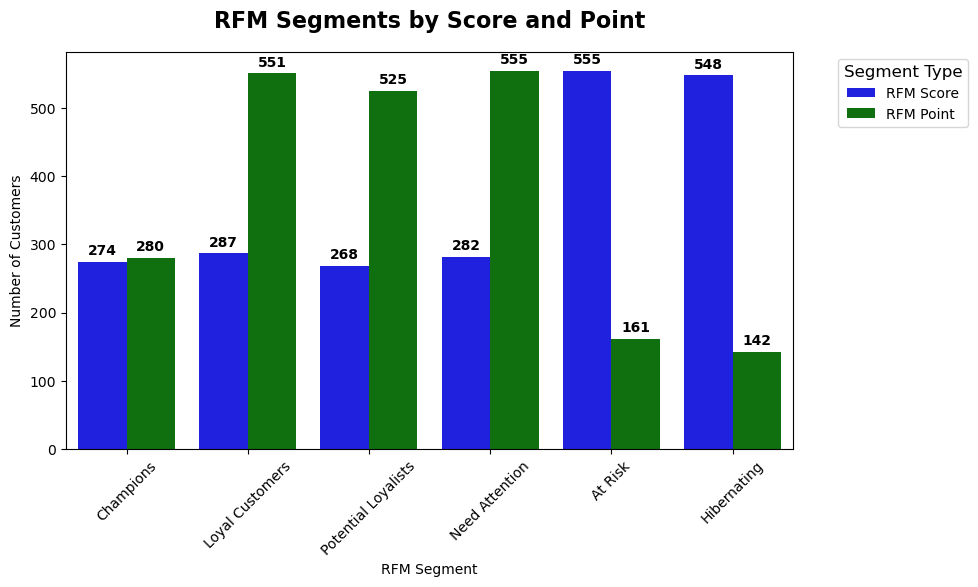


- Distribution of Segments based on RFM Points is more successful in identifying the most valuable customers, even though the distribution is left skewed.
- We will continue the analysis using RFM Points for segmentation, as it provides a more balanced view of customer value and engagement.


In [33]:
# Get counts
index_ = ['Champions', 'Loyal Customers', 'Potential Loyalists', 'Need Attention', 'At Risk', 'Hibernating']
score_counts = rfm_data['RFM_score_segment'].value_counts().reindex(index_)
point_counts = rfm_data['RFM_point_segment'].value_counts()

# Create dataframe
plot_data = pd.DataFrame({
    'Segment': score_counts.index,
    'RFM Score': score_counts.values,
    'RFM Point': point_counts.reindex(score_counts.index).values
})

# Convert to long format
plot_data = plot_data.melt(
    id_vars='Segment',
    var_name='Type',
    value_name='Count'
)

print("RFM Score skewness:", round(rfm_data['RFM_Score'].skew(), 4))
print("RFM Point skewness:", round(rfm_data['RFM_Points'].skew(), 4))


# Plot
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x='Segment',
    y='Count',
    hue='Type',
    palette=['blue', 'green'],
    ax=ax
)

# Annotate bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%d',
        padding=3,
        fontsize=10,
        fontweight='bold'
    )

# Formatting
ax.set_title(
    "RFM Segments by Score and Point",
    fontsize=16,
    fontweight='bold',
    y=1.04
)

ax.set_xlabel("RFM Segment")
ax.set_ylabel("Number of Customers")

ax.legend(title="Segment Type", title_fontsize=12, fontsize=10, bbox_to_anchor=(1.25, 1), loc='upper right', fancybox=True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display_md("""
- Distribution of Segments based on RFM Points is more successful in identifying the most valuable customers, even though the distribution is left skewed.
- We will continue the analysis using RFM Points for segmentation, as it provides a more balanced view of customer value and engagement.
""")


#### **Visualization : RFM Points Segment**

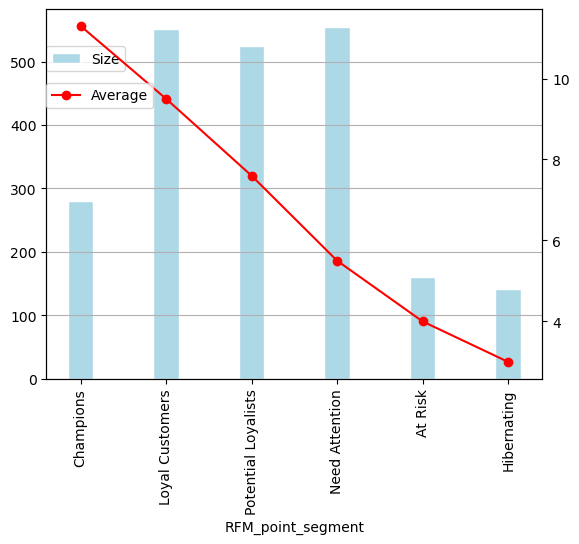

In [34]:
fig, ax = plt.subplots()
rfm_point_summary['Customer_Count'].plot(kind='bar', ax=ax, color='lightblue', edgecolor='white', label='Size', width=0.3)
ax.legend(bbox_to_anchor=(0.0, 0.90), loc=2, borderaxespad=0.)

ax1 = ax.twinx()
rfm_point_summary['Average_RFM_Points'].plot(kind='line', ax=ax1, color='red', marker='o', label='Average')
ax1.legend(bbox_to_anchor=(0.0, 0.80), loc=2, borderaxespad=0.)
ax.grid(axis='y')

plt.show()


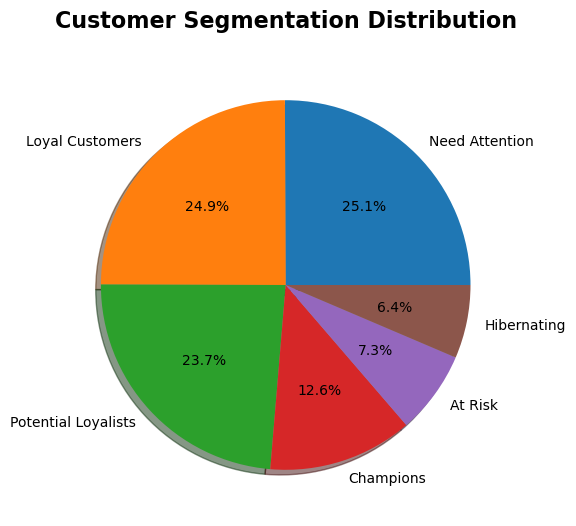

In [35]:
plt.figure(figsize=(6,6))

plt.pie(point_counts, labels = point_counts.index, autopct='%1.1f%%',shadow=True,startangle=0)
#plt.legend(point_counts.index, bbox_to_anchor=(1.45,0.5), loc='center right')
plt.title('Customer Segmentation Distribution', fontsize=16, fontweight='bold', y=1.04)
plt.axis('off')
plt.show()


<Figure size 1500x1500 with 0 Axes>

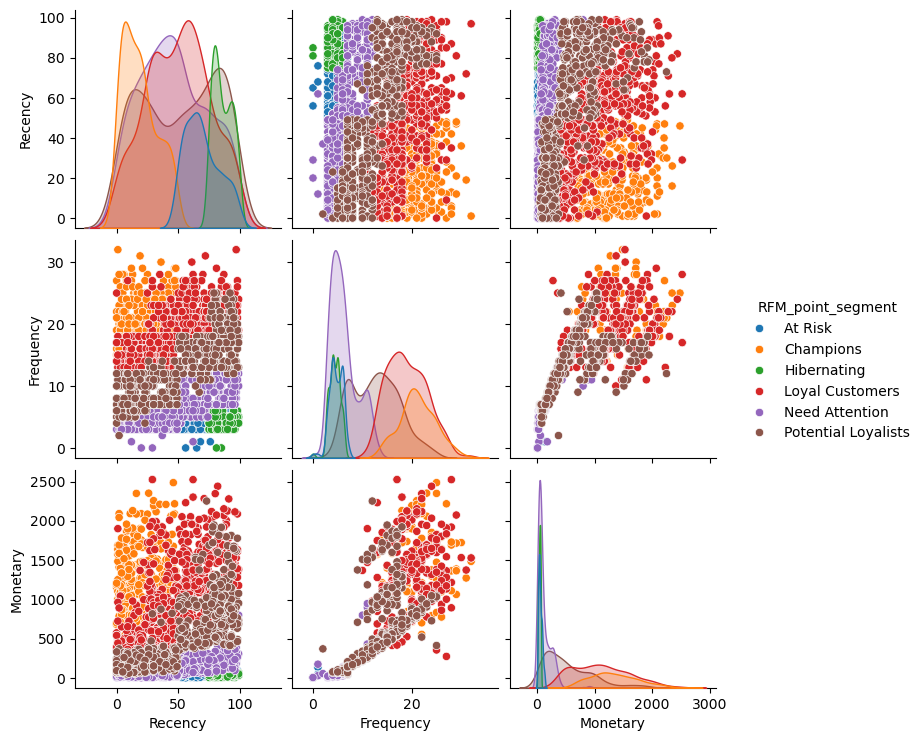


There is no clear or meaningful pattern visible in the graph. Scaling the features may help reveal the underlying patterns more effectively.


In [36]:
plt.figure(figsize=(15,15))
df_rfm = rfm_data.sort_values('RFM_point_segment')
sns.pairplot(df_rfm[['Recency', 'Frequency', 'Monetary','RFM_point_segment']],hue='RFM_point_segment')

plt.show()
display_md("""
There is no clear or meaningful pattern visible in the graph. Scaling the features may help reveal the underlying patterns more effectively.
""")


<Figure size 2000x2000 with 0 Axes>

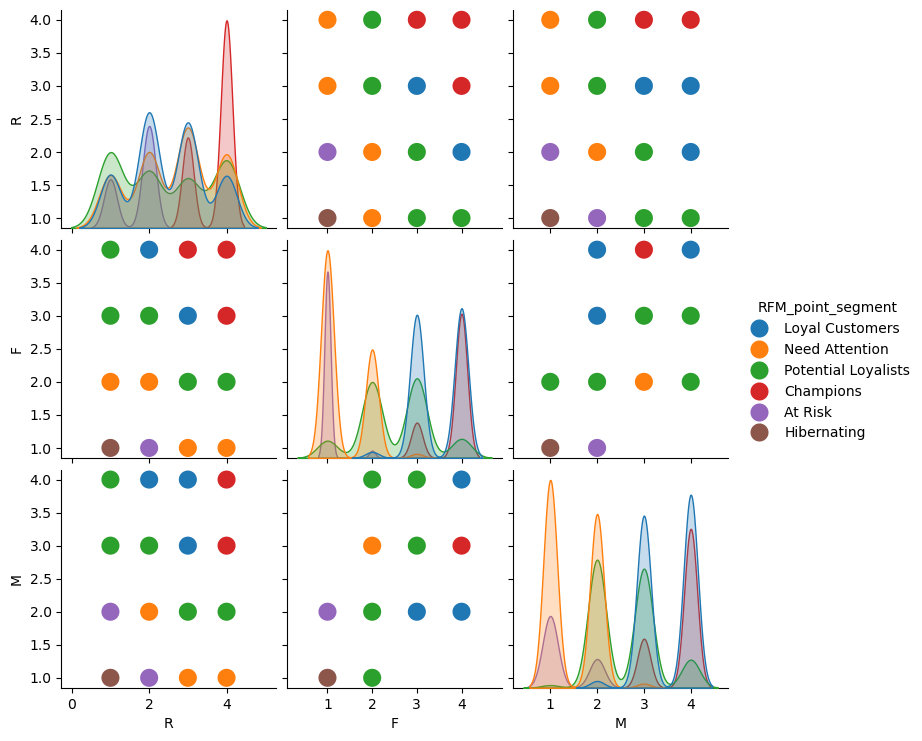

In [37]:
plt.figure(figsize=(20,20))
sns.pairplot(rfm_data[['R', 'F', 'M','RFM_point_segment']],
             hue='RFM_point_segment',plot_kws={"s": 200})
plt.show()

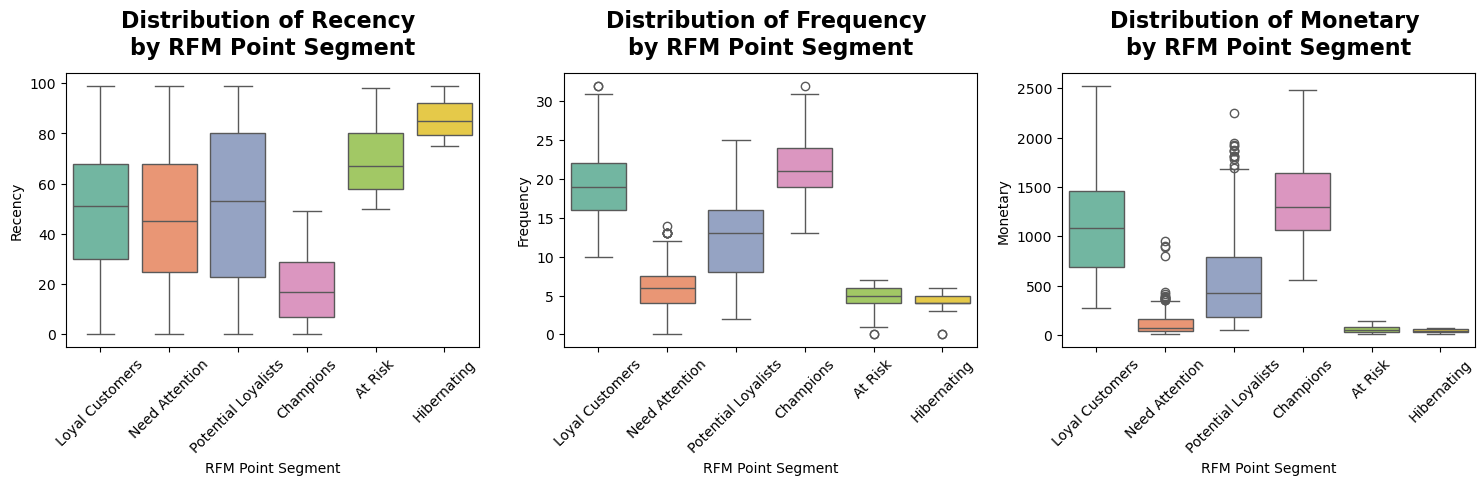

In [38]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
cols = ['Recency', 'Frequency', 'Monetary']
for i, col in enumerate(cols):
    sns.boxplot(x='RFM_point_segment', y=col, data=rfm_data, ax=ax[i], palette='Set2')
    ax[i].set_title(f'Distribution of {col} \nby RFM Point Segment', fontsize=16, fontweight='bold', y=1.04)
    ax[i].set_xlabel('RFM Point Segment')
    ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=45)
    ax[i].set_ylabel(col)

plt.tight_layout()
plt.show()


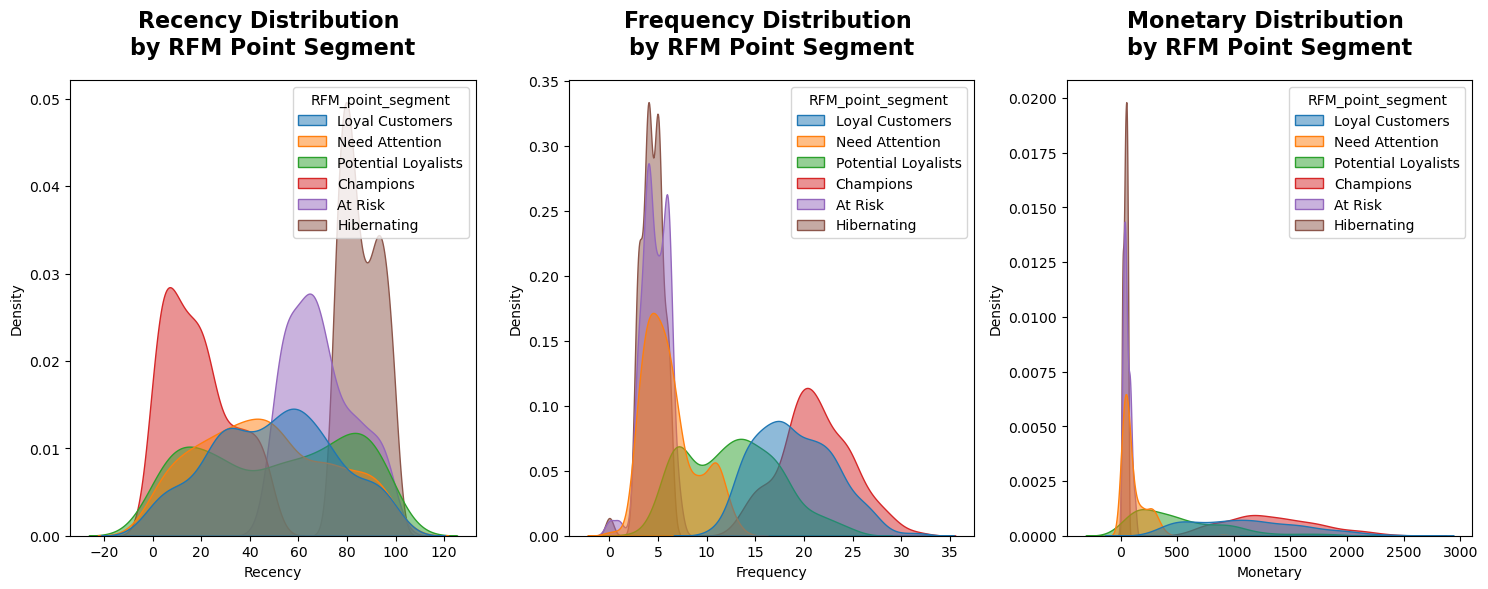

In [39]:
fig, ax = plt.subplots(1, 3, figsize=(15, 6))
for i, col in enumerate(cols):
    sns.kdeplot(data=rfm_data, x=col, hue='RFM_point_segment', shade=True, common_norm=False, alpha=0.5, ax=ax[i])
    ax[i].set_title(f"{col} Distribution \nby RFM Point Segment", fontsize=16, fontweight='bold', y=1.04)
    ax[i].set_xlabel(col)
    ax[i].set_ylabel('Density')
plt.tight_layout()
plt.show()


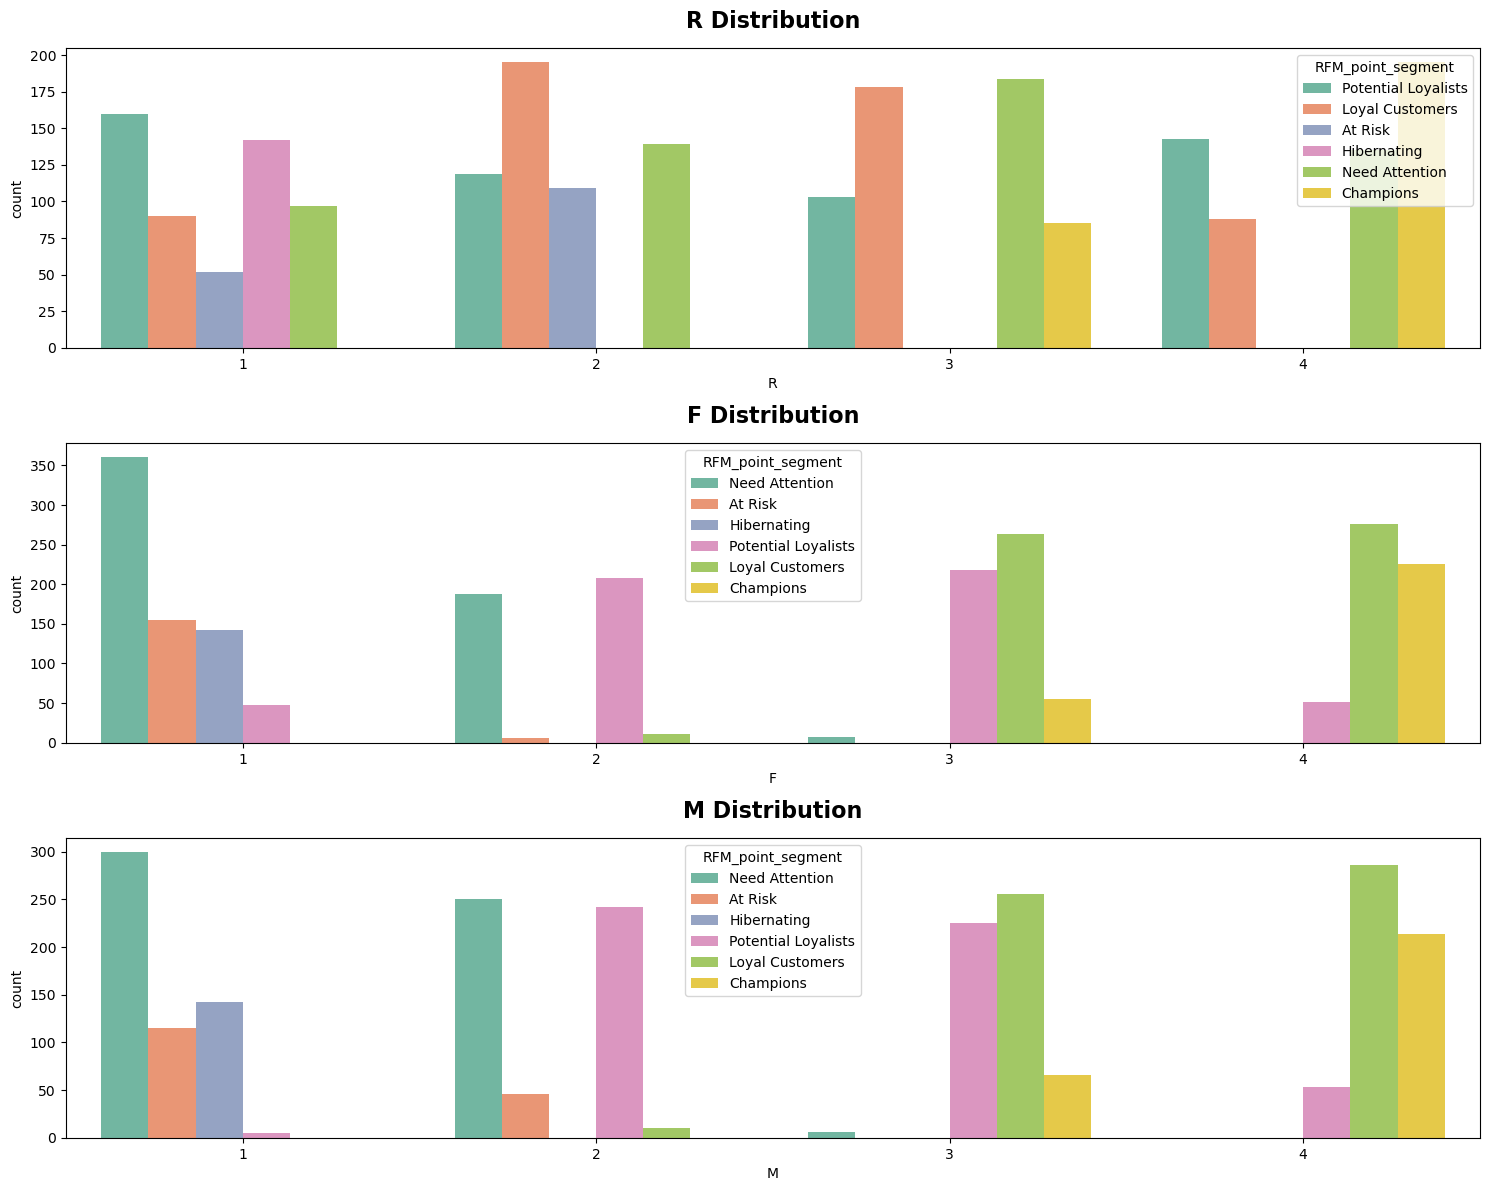

In [40]:
fig, ax = plt.subplots(3, 1, figsize=(15, 12))
ax=ax.flatten()
columns = ['R', 'F', 'M']
for i, col in enumerate(columns):
    sns.countplot(data=rfm_data, x=col, hue='RFM_point_segment', palette='Set2', ax=ax[i])
    ax[i].set_title(f"{col} Distribution", fontsize=16, fontweight='bold', y=1.04)

plt.tight_layout()
plt.show()


In [41]:
# Concatenate rfm_data and processed_df to form the complete dataset.

full_df = pd.merge(processed_df.drop(columns=['Recency', 'Monetary', 'Frequency']), rfm_data, on='ID',how='left')
full_df.head()


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Is_parent,Children,Day,Month,Quarter,Year,Tenure,Recency,Frequency,Monetary,Avg_spending,R,F,M,RFM_Score,RFM_score_segment,RFM_Points,RFM_point_segment
0,5524,1957,Graduation,Single,58138.00,0,0,2012-09-04,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,58,0,0,4,9,3,2012,28,58,22,1617,73.50,2,4,4,244,At Risk,10,Loyal Customers
1,2174,1954,Graduation,Single,46344.00,1,1,2014-03-08,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,61,1,2,8,3,1,2014,9,38,4,27,6.75,3,1,1,311,Need Attention,5,Need Attention
2,4141,1965,Graduation,Partner,71613.00,0,0,2013-08-21,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,50,0,0,21,8,3,2013,16,26,20,776,38.80,3,4,3,343,Potential Loyalists,10,Loyal Customers
3,6182,1984,Graduation,Partner,26646.00,1,0,2014-02-10,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,31,1,1,10,2,1,2014,10,26,6,53,8.83,3,1,1,311,Need Attention,5,Need Attention
4,5324,1981,PhD,Partner,58293.00,1,0,2014-01-19,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,34,1,1,19,1,1,2014,11,94,14,422,30.14,1,3,3,133,At Risk,7,Potential Loyalists


**3.3. Segmentation Recognition**

__3.3.1. Cluster by Income & Monetary__

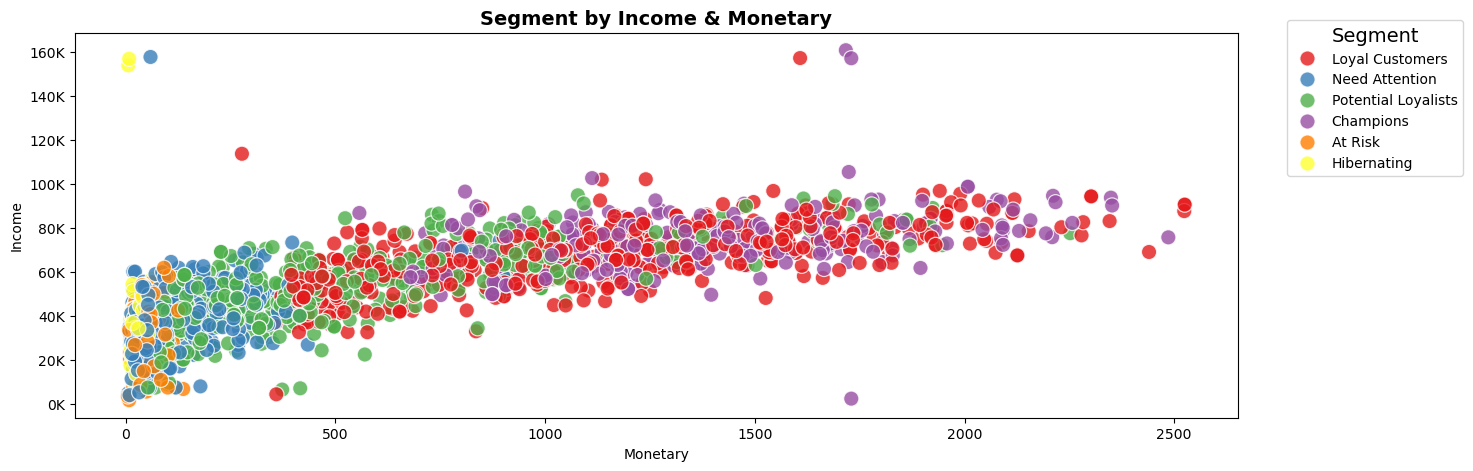

In [42]:
import matplotlib as mpl
from matplotlib.ticker import FuncFormatter
fig, ax = plt.subplots(figsize=(15, 5))

sns.scatterplot(
    data=full_df,
    x='Monetary',
    y='Income',
    hue='RFM_point_segment',              
    palette=sns.color_palette(palette='Set1', n_colors=full_df['RFM_point_segment'].nunique()),      
    alpha=0.8,                   
    s=120                        
)

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
ax.set_title("Segment by Income & Monetary", fontsize=14, fontweight='bold')
ax.legend(title='Segment', title_fontsize=14, bbox_to_anchor=(1.2, 1.05), loc='upper right', fancybox=True)

plt.show()


We've created segments and analyzed their purchasing, spending habits; now let’s identify the customers within each group.


In [43]:
full_df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Is_parent,Children,Day,Month,Quarter,Year,Tenure,Recency,Frequency,Monetary,Avg_spending,R,F,M,RFM_Score,RFM_score_segment,RFM_Points,RFM_point_segment
0,5524,1957,Graduation,Single,58138.00,0,0,2012-09-04,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,58,0,0,4,9,3,2012,28,58,22,1617,73.50,2,4,4,244,At Risk,10,Loyal Customers
1,2174,1954,Graduation,Single,46344.00,1,1,2014-03-08,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,61,1,2,8,3,1,2014,9,38,4,27,6.75,3,1,1,311,Need Attention,5,Need Attention
2,4141,1965,Graduation,Partner,71613.00,0,0,2013-08-21,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,50,0,0,21,8,3,2013,16,26,20,776,38.80,3,4,3,343,Potential Loyalists,10,Loyal Customers
3,6182,1984,Graduation,Partner,26646.00,1,0,2014-02-10,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,31,1,1,10,2,1,2014,10,26,6,53,8.83,3,1,1,311,Need Attention,5,Need Attention
4,5324,1981,PhD,Partner,58293.00,1,0,2014-01-19,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,34,1,1,19,1,1,2014,11,94,14,422,30.14,1,3,3,133,At Risk,7,Potential Loyalists


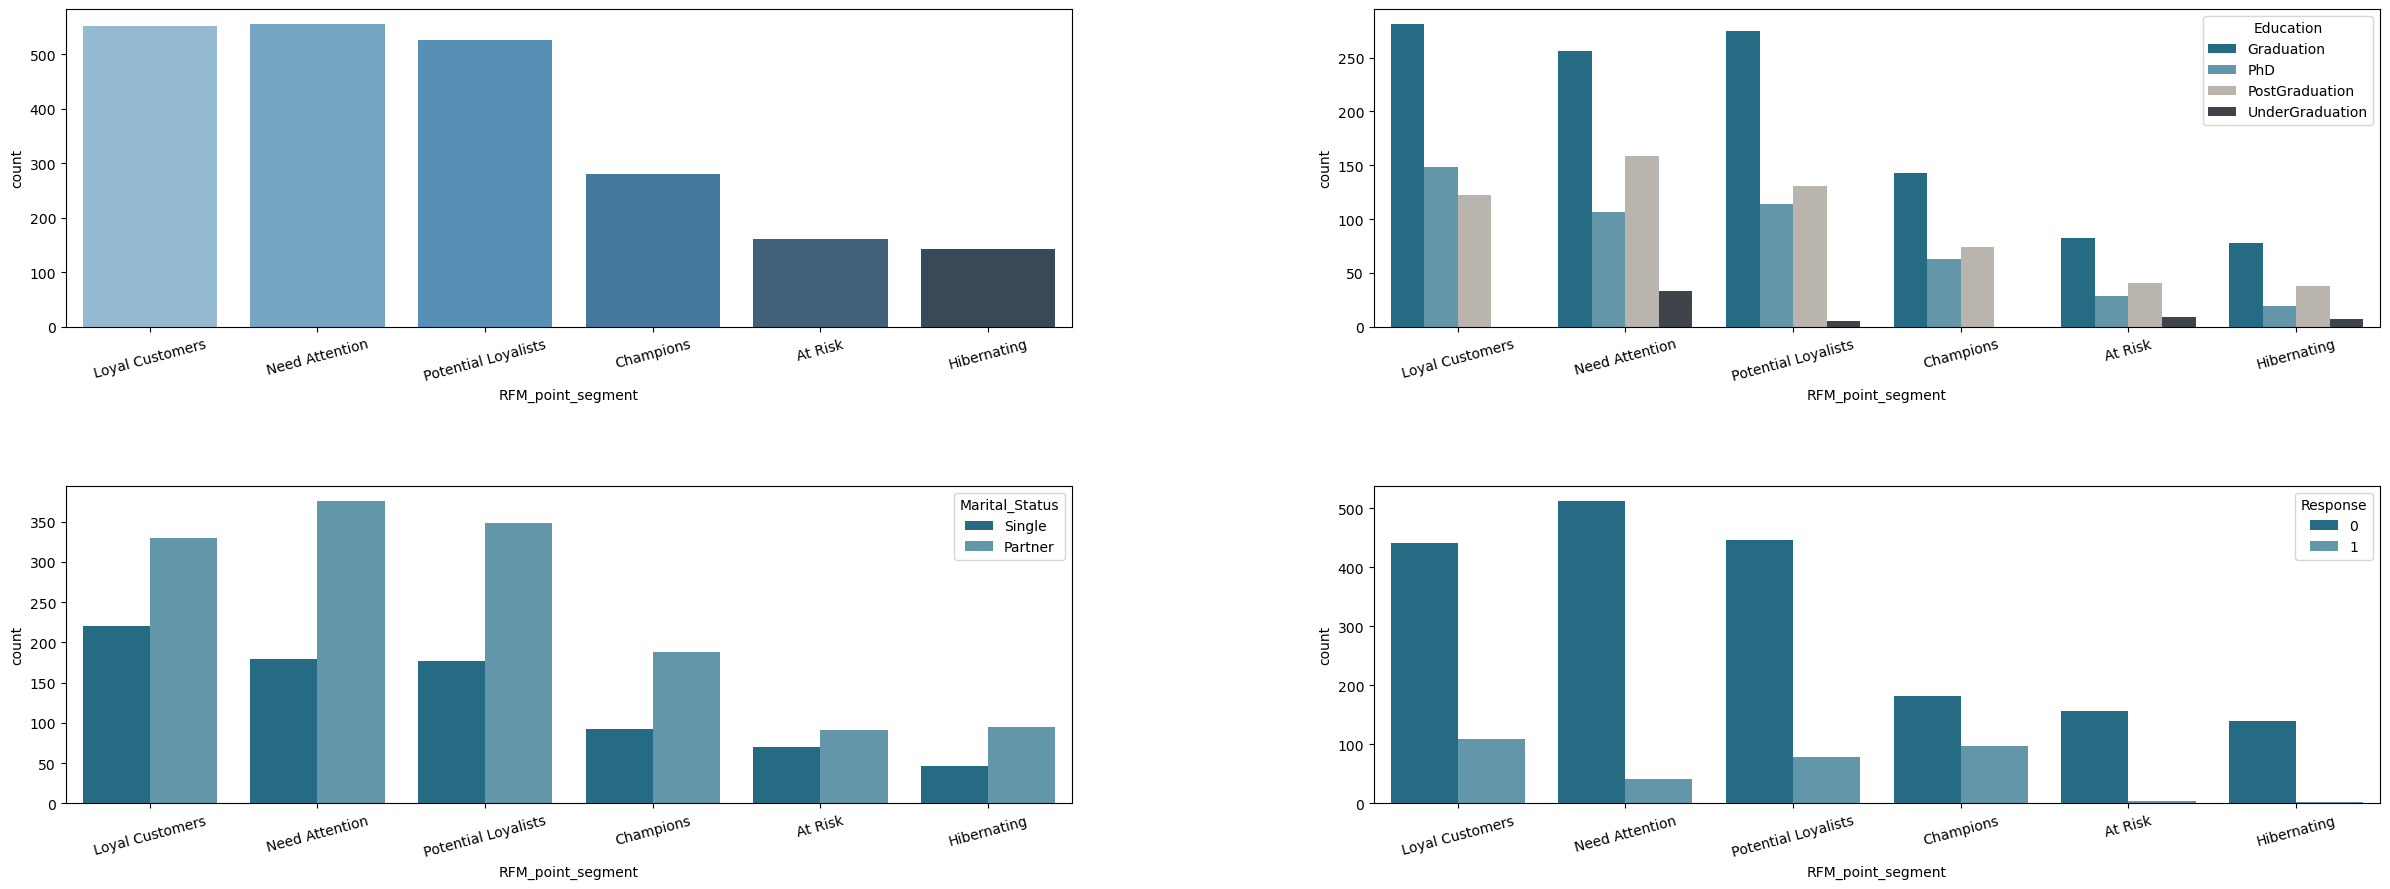

In [44]:

# Create a 2x2 grid layout
fig, ax = plt.subplots(2, 2, figsize=(24, 9))

# Plot 1: Segment counts
sns.countplot(x="RFM_point_segment", data=full_df, palette="Blues_d", ax=ax[0,0])
ax[0,0].tick_params(axis='x', rotation=25, labelrotation=15)

# Plot 2: Segment vs Education
sns.countplot(x="RFM_point_segment", hue="Education", data=full_df,
              palette=['#157394','#589cb4','#bcb4ac','#3c444c'], ax=ax[0,1])
ax[0,1].tick_params(axis='x', rotation=25, labelrotation=15)


# Plot 3: Segment vs Marital_Status
sns.countplot(x="RFM_point_segment", hue="Marital_Status", data=full_df,
              palette=['#157394','#589cb4'], ax=ax[1,0])
ax[1,0].tick_params(axis='x', rotation=25, labelrotation=15)

# Plot 4: Segment vs Response
sns.countplot(x="RFM_point_segment", hue="Response", data=full_df,
              palette=['#157394','#589cb4'], ax=ax[1,1])
ax[1,1].tick_params(axis='x', rotation=25, labelrotation=15)

plt.tight_layout()
plt.subplots_adjust(wspace=0.3, hspace=0.5)
plt.show()


**Insights :**

- 

**3.3.3. Spending Habits by Segment**

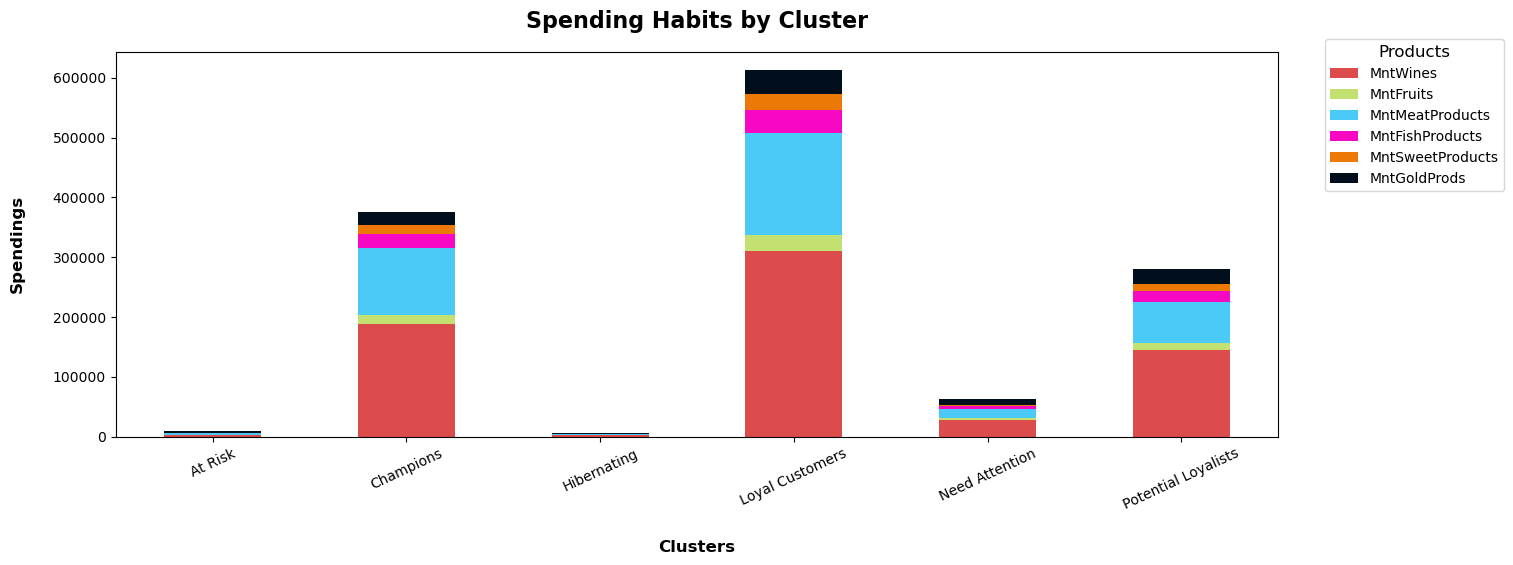

In [45]:
cluster_spendings = full_df.groupby('RFM_point_segment')[['MntWines', 'MntFruits','MntMeatProducts', 
                                                  'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']].sum()

cluster_spendings.plot(kind='bar', stacked=True, figsize=(15, 5), color=['#dc4c4c',"#c3e170","#4BC9F7","#f709c3","#ec7906","#010F1D"])

plt.title('Spending Habits by Cluster', fontsize=16, fontweight='bold', y=1.04)
plt.xlabel('Clusters', fontsize=12, labelpad=20, fontweight='bold')
plt.ylabel('Spendings', fontsize=12, labelpad=20, fontweight='bold')
plt.legend(title='Products', title_fontsize=12, bbox_to_anchor=(1.2, 1.05), fancybox=True)
plt.xticks(rotation=25, ha='center')

plt.show()


**Insight :**

- Customers from all segments have spent most of their money on Wine and Meat products.
- Customers from all segments have spent least of their money on Fruits and Sweet products.

**3.3.4. Purchasing Habits by Segment**

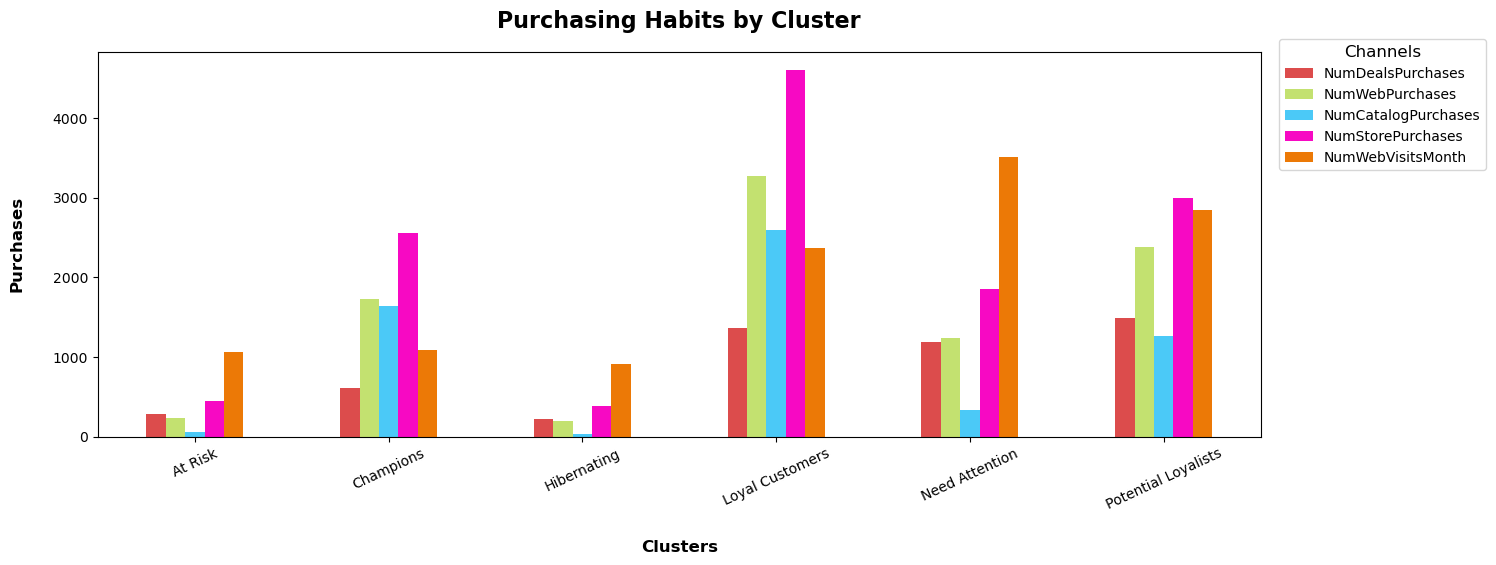

In [46]:
cluster_purchases = full_df.groupby('RFM_point_segment')[['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
                                                  'NumStorePurchases', 'NumWebVisitsMonth']].sum()

cluster_purchases.plot(kind='bar', color=['#dc4c4c',"#c3e170","#4BC9F7","#f709c3","#ec7906"], figsize=(15, 5))

plt.title('Purchasing Habits by Cluster', fontsize=16, fontweight='bold', y=1.04)
plt.xlabel('Clusters', fontsize=12, labelpad=20, fontweight='bold')
plt.ylabel('Purchases', fontsize=12, labelpad=20, fontweight='bold')
plt.legend(title='Channels', title_fontsize=12, bbox_to_anchor=(1.2, 1.05), fancybox=True)
plt.xticks(rotation=25, ha='center')

plt.show()


**Insights :**

- `Loyal` and `At risk` segment customers mostly tend to make purchases in stores. 
- Most web and catalog purchases are also made by customers from the `Loyal` and `At risk` segments. 
- `Potential Loyalists` and `Can't Loose` segments also like to buy from stores. 
- Deal purchases are common among `At risk` and `Potential Loyalists` segment. 
- `Hibernating` segment customers make the most web visits, while `Need Attention` segment customers have the fewest web visits.


**3.3.5. Promotions Acceptance by Segment**

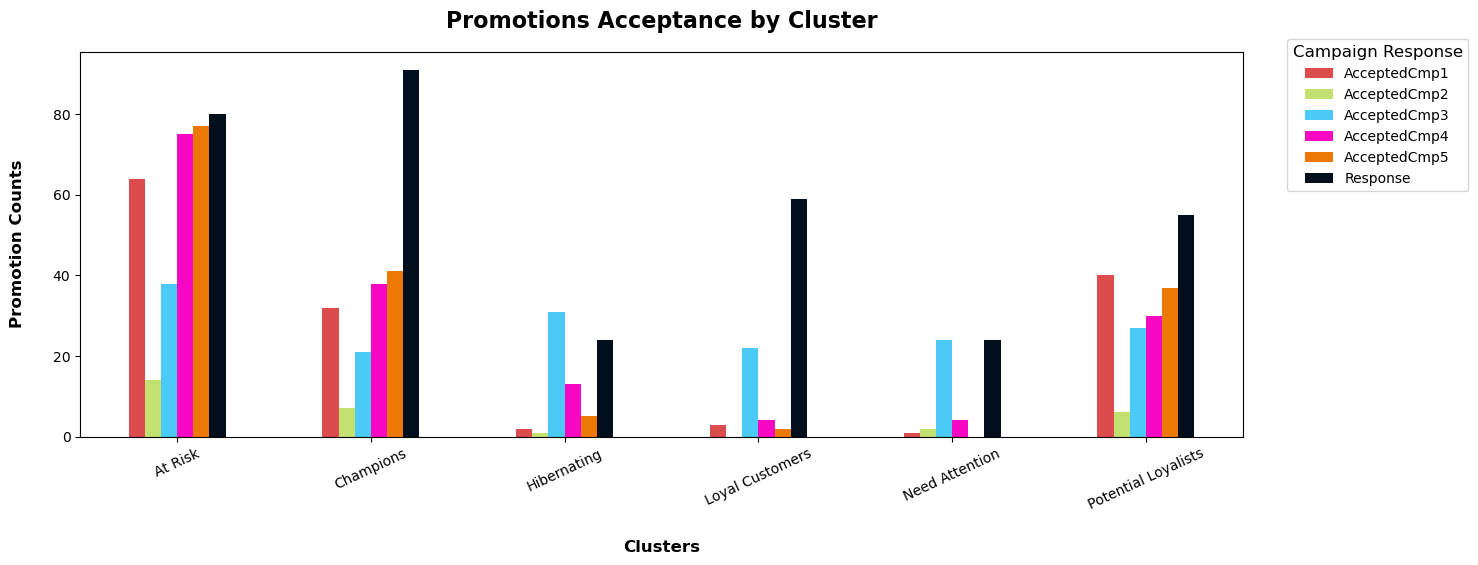

In [47]:
cluster_campaign = full_df.groupby('RFM_score_segment')[['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 
                                                  'AcceptedCmp5', 'Response']].sum()


cluster_campaign.plot(kind='bar', color=['#dc4c4c',"#c3e170","#4BC9F7","#f709c3","#ec7906","#010F1D"],figsize=(15,5))

plt.title('Promotions Acceptance by Cluster', fontsize=16, fontweight='bold', y=1.04)
plt.xlabel('Clusters', fontsize=12, labelpad=20, fontweight='bold')
plt.ylabel('Promotion Counts', fontsize=12, labelpad=20, fontweight='bold')
plt.legend(title='Campaign Response', title_fontsize=12, bbox_to_anchor=(1.2, 1.05), fancybox=True)
plt.xticks(rotation=25, ha='center')

plt.show()


**Insights :**

- `Loyal customers` segment receive most of the company's offers. 
- Campaigns 1, 5, and the last one seem to be the most successful. 
- The `About to sleep` segment shows the lowest interest in the company's promotional campaigns.


In [48]:
# save the dataset which constructed using KMeans clustering +elbow method to predict high-value buyer and perform pareto analysis
kmeans_cluster_df.to_csv(parent_path.joinpath('data', 'processed', 'kmeans_df.csv'), index=False)
print("="*20, "KMeans Dataset saved successfully.", "="*20)


==================== KMeans Dataset saved successfully. ====================


In [49]:
# Sav full dataframe for profiling of customers
full_df.to_csv(parent_path.joinpath('data', 'processed', 'customer_segmentation.csv'), index=False)
print("="*20, "Complete Dataset saved successfully.", "="*20)


==================== Complete Dataset saved successfully. ====================


### **Conclusion:**

Based on the Machine Learning model (K-Means Clustering ) applied to customer transaction data, we have uncovered a clear insight.

**Distinct Segmentation Exist :** K-Means clustering successfully separated our customers into "VIP" (High Value), "Loyal High Spenders" (Emerging high Value) , "Frequent Budget Buyers"(Mid Value) , and "At-Risk" (Low Value/Churning) clusters.

#### **Strategic Recommendations for Business Growth**

__1. Shift Marketing Spent from Acquisition to Retention(Maximize ROI)__

- **Problem**: Acquiring new customers is costly, and most only purchase/buy once.

- **Solution**: Redirect a portion of the marketing budget (e.g., 30%) from acquisition efforts toward customer retention initiatives, such as a **VIP loyalty program**. Since purchase frequency is the strongest driver of lifetime value, rewarding "Champions" for repeat purchases delivers higher and safer ROI than broad acquisition campaigns. Also, don't forget **Loyal Regulars spenders**: Retention + upselling to convert them into VIP customers.

__2. Smarter Email Marketing__

- **Problem**: Current email campaigns treat all customers the same.

- **Solution**: Use ML based customer segmentation to deliver personalized emails:
    
    - Mid-Tier Customers: Personalized `upsell` and `cross-sell` offers to grow basket size.

    - At-Risk Customers: When customer recency exceeds a predefined threshold (e.g., 60 days without a purchase), automatically send a "We miss you" `discount` (e.g., 25% off) to prevent churn.

__3. Inventory Optimization for High-Value Customers Preferences__

- **Problem**: Stockouts of popular products can negatively impact customer satisfaction and loyalty, particularly among top-buyers customer segment.

- **Solution**: Cross-check purchases of the "Champions" cluster. Ensure their favorite SKUs are always available, and give them early access to new products or product variations before their general market release.

    

### **Future Work:** 

In the next notebook, we will utilize a dataset constructed through __KMeans clustering + elbow method__, saved as `kmeans_df.csv`. This dataset will serve as the foundation for performing __High-Value Customer Prediction__ and conducting __Pareto Analysis__ to generate deeper __Revenue Insights__.